# Система прогнозирования отмены бронирования отеля
Автор: Перепелюк Иван

**Суть проекта:** реализовать модель машинного обучения для прогнозирования отмены бронирования отеля с целью повышения выручки и снижения репутационных рисков для сети отелей UrbanStay.

**Бизнес-идея:** уйти от классического "овербукинга" (Овербукинг (от англ. overbooking - «перебронирование») - это практика, при которой компания принимает больше бронирований, чем может реально обслужить. Цель - снизить финансовые потери за счёт того, что часть клиентов не воспользуется услугой или отменит бронирование.), являющегося не совсем надёжным вариантом для большой сети, к прогнозированию при помощи ML модели, которая поможет предварительно распознавать отмену бронирования со стороны клиента.

**Предоставленные данные:**

Аналитики UrbanStay предоставили 2 таблицы, в формате SQL. При первичной обработке данных выгрузим их при помощи SQLAlchemy.

**Таблица 1** - данные об истории бронирования:
- booking_id - Уникальный номер брони. С помощью него можно идентифицировать каждое бронирование в системе. Пример номера брони: INN000001310.
- booking_date - Дата оформления брони: например, 18.06.2018.
- sales_channel - Способ оформления брони
- adult_count - Количество взрослых гостей, которые планируют заселиться в отель. Например, 2 означает, что в рамках брони в отель планируют заехать как минимум двое взрослых, не считая детей.
- child_count - Количество детей, которые заселятся в отель в рамках брони. Например, 0 означает, что детей среди ожидаемых гостей нет.
- returning_customer - Отметка о том, что клиенты уже бронировали номера в сети отелей. 1 - бронь уже была, 0 - новый клиент.
- previous_cancellations - Количество отменённых бронирований у клиента в прошлом. Например, 0 означает, что клиент ни разу не отменял бронирование, а 2 - что он два раза отменял бронь.
- previous_no_shows	Сколько раз клиент бронировал номер и по итогу заселялся. 1 означает, что клиент один раз действительно заехал по своей брони, 0 - пока подтверждений брони не было.
- booking_value	Итоговая стоимость бронирования в рублях.
- days_until_checkin - Количество дней с момента брони до даты заселения. Например, 204 означает, что между бронью и заездом должно было пройти 204 дня.
- weekend_nights - Количество ночей в периоде проживания, которые приходятся на выходные дни - субботу и воскресенье. Например, 4 означает, что гости будут проживать четыре ночи в выходные дни.
- weekday_nights - Количество ночей в периоде проживания, которые приходятся на будние дни: с понедельника по пятницу. Например, 2 означает, что гости будут проживать две ночи в будние дни.
- meal_plan	- Выбранный гостями тип питания. Примеры значений: тип_питания_1, тип_питания_2.
- parking_included - Информация о бронировании парковочного места. Например, 0 означает, что парковка не бронировалась.
- room_type	- Категория номера или номеров в брони. Примеры значений: тип_1, тип_4.
- customer_special_requests	- Количество комментариев и пожеланий клиента: например, просьб о дополнительной кровати, раннем заезде и так далее.
- booking_status - Целевая переменная, обозначает текущий статус бронирования (отменено или нет).

**Таблица 2** - данные по истории отзывов о проживании:
- customer_id - Уникальный идентификатор клиента, например, C0003. Используется, чтобы связать отзыв и его автора, конкретного гостя.
- booking_id - Идентификатор брони, по которой оставлен отзыв. Например, INN000201614 - это номер бронирования, который связывает отзыв с конкретной поездкой.
- review_date - Дата, когда клиент оставил отзыв: например, 2018-11-21. Показывает, когда была получена обратная связь.
- stay_rating - Оценка, которую клиент поставил проживанию. 1 - низший балл, 5 - высший балл.
- review_text - Развёрнутый комментарий клиента о проживании. В этом поле содержится качественная обратная связь: что понравилось, а что нет. Пример отзыва: «Неплохо. Приветливый персонал на ресепшн, но завтрак однообразный. Питание в ресторане понравилось».

**План проекта:**

1. Подготовка данных

2. Моделирование

3. Расчёт экономической эффективности модели

4. Выводы по проекту

## Перевод бизнес-задачи на язык машинного обучения

Для реализации поставленной задачи будем использовать следующие технологии машинного обучения.

1. Выбор модели

Будут обучены и сопоставлены две модели:

- Random Forest;
- CatBoost.

Лучшая модель выбирается по экономической метрике Incremental Revenue.

2. Подбор гиперпараметров

Воспользуемся библиотекой Optuna для подбора наилучших гиперпараметров модели, для макисмального прироста показателей метрик.

3. Калибровка вероятностей

Так как работаем с задачей классификации, для финальной модели необходимо откалибровать вероятности (чтобы предсказания модели были равны процентной доли реальной картины, например вероятностное предсказание модели класса 0 = 0.8, следовательно 8 из 10 клиентов будут относиться к классу 0)

4. Метрики

Будем оценивать модель как классическими метриками (F1, Accuracy, Precision, Recall), так и экономическими, ведь главная цель - прирост выручки предприятия. Для этого будет необходимо реализовать функцию для расчёта экономической метрики: Incremental Revenue.

## Загрузка необходимых библиотек

In [35]:
# Установка необходимых библиотек

# Стандартные библиотеки
import time
import warnings
import os
import pickle
from datetime import datetime

# Математика и массивы
import numpy as np
import scipy as sp

# Работа с данными
import pandas as pd

# Подключение к базе данных
from sqlalchemy import create_engine

# Корреляционный анализ
from phik import phik_matrix

# Машинное обучение - предобработка и пайплайны
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold,
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder,
)

# Машинное обучение - метрики
from sklearn.metrics import (
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    brier_score_loss,
    make_scorer,
)

# Машинное обучение - модели
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# Калибровка модели
from sklearn.calibration import CalibratedClassifierCV, calibration_curve

# Векторизация текста
from sklearn.feature_extraction.text import TfidfVectorizer

# Градиентный бустинг
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

# Подбор гиперпараметров
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# Анализ важности признаков
import shap

# Визуализация
import matplotlib.pyplot as plt
import seaborn as sns

# Настройка отображения
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Константы воспроизводимости и кросс-валидации
RANDOM_STATE = 42
CV = 3            # количество фолдов согласно заданию
VAL_SIZE = 2000   # размер валидационной выборки согласно заданию

# Константы для расчёта Incremental Revenue
AVG_REV      = 64_500  # средний доход от сдачи одного номера, руб.
COST_FP      = 7_000   # стоимость одного ложного предсказания отмены, руб.
LOST_REV     = 64_500  # упущенный доход от одной отменённой брони, руб.
PER_REBOOKING = 45_000 # доход от повторной сдачи номера после отмены, руб.


print('Библиотеки успешно загружены, константы объявлены.')

Библиотеки успешно загружены, константы объявлены.


## Этап 1: подготовка данных

### Загрузка данных

Подключение к базе данных PostgreSQL выполняется через SQLAlchemy. Параметры доступа читаются из переменных окружения (файл `.env`, образец в `.env.example`).

Используемые таблицы: `hotel_bookings` (бронирования) и `hotel_reviews` (отзывы).

In [2]:
# Этап 1. Подготовка данных
# Шаг 1.1. Загрузка данных

# Параметры подключения читаются из переменных окружения (файл .env, см. .env.example)
from dotenv import load_dotenv
from sqlalchemy.engine import URL

load_dotenv()

# Строка подключения собирается через URL.create: спецсимволы пароля экранируются автоматически
connection_url = URL.create(
    'postgresql+psycopg2',
    username=os.environ['DB_USER'],
    password=os.environ['DB_PASSWORD'],
    host=os.environ['DB_HOST'],
    port=int(os.environ.get('DB_PORT', 6432)),
    database=os.environ['DB_NAME_HOTELS'],
)
engine = create_engine(connection_url)

# Загрузка таблицы бронирований
query_bookings = 'SELECT * FROM hotel_bookings;'
df_bookings = pd.read_sql_query(query_bookings, engine)

# Загрузка таблицы отзывов
query_reviews = 'SELECT * FROM hotel_reviews;'
df_reviews = pd.read_sql_query(query_reviews, engine)

print('Данные успешно загружены.')
print(f'Таблица бронирований: {df_bookings.shape[0]} строк, {df_bookings.shape[1]} столбцов.')
print(f'Таблица отзывов:      {df_reviews.shape[0]} строк, {df_reviews.shape[1]} столбцов.')

Данные успешно загружены.
Таблица бронирований: 35341 строк, 17 столбцов.
Таблица отзывов:      25177 строк, 5 столбцов.


In [3]:
# Первичный осмотр таблицы бронирований
print('Таблица hotel_bookings - первые строки:')
display(df_bookings.head())

print('\nТипы данных и пропуски:')
display(df_bookings.info())

Таблица hotel_bookings - первые строки:


,booking_id,booking_date,sales_channel,adult_count,child_count,returning_customer,previous_cancellations,previous_no_shows,booking_status,booking_value,days_until_checkin,weekday_nights,weekend_nights,meal_plan,parking_included,room_type,customer_special_requests
0,INN00000,2020-07-08,корпоративное_бронирование,300,0,False,0,0,нет_отказа,6700.0,21,1,0,тип_питания_2,False,тип_1,0
1,INN00001,2021-09-19,корпоративное_бронирование,3,0,True,0,1,нет_отказа,62300.0,15,5,2,тип_питания_2,False,тип_1,1
2,INN00002,2022-11-19,корпоративное_бронирование,3,0,True,0,2,нет_отказа,46900.0,96,5,2,тип_питания_1,False,тип_1,0
3,INN00003,2017-02-11,онлайн_бронирование,2,0,False,0,0,нет_отказа,53600.0,150,6,2,тип_питания_1,False,тип_1,0
4,INN00004,2019-03-06,корпоративное_бронирование,1,0,True,1,1,нет_отказа,46900.0,96,5,2,тип_питания_1,False,тип_1,1



Типы данных и пропуски:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35341 entries, 0 to 35340
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   booking_id                 35341 non-null  object 
 1   booking_date               35341 non-null  object 
 2   sales_channel              35341 non-null  object 
 3   adult_count                35341 non-null  int64  
 4   child_count                35341 non-null  int64  
 5   returning_customer         35341 non-null  bool   
 6   previous_cancellations     35341 non-null  int64  
 7   previous_no_shows          35341 non-null  int64  
 8   booking_status             35341 non-null  object 
 9   booking_value              35341 non-null  float64
 10  days_until_checkin         35341 non-null  int64  
 11  weekday_nights             35341 non-null  int64  
 12  weekend_nights             35341 non-null  int64  
 13  meal_plan            

None

In [4]:
# Первичный осмотр таблицы отзывов
print('Таблица hotel_reviews - первые строки:')
display(df_reviews.head())

print('\nТипы данных и пропуски:')
display(df_reviews.info())

Таблица hotel_reviews - первые строки:


,customer_id,booking_id,review_date,stay_rating,review_text
0,C0001,INN00000,2020-08-21,3,"Неплохо. тихо и спокойно, но отсутствие фена в..."
1,C0001,INN00001,2021-10-15,3,"Неплохо. красивое оформление территории, но не..."
2,C0001,INN00002,2023-03-08,4,Отличный отель! удобные парковочные места. зде...
3,C0002,INN00003,2017-08-13,3,"Неплохо. тёплый приём, но неисправная сантехни..."
4,C0003,INN00004,2019-07-12,4,Отличный отель! качественная косметика в ванно...



Типы данных и пропуски:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25177 entries, 0 to 25176
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   customer_id  25177 non-null  object
 1   booking_id   25177 non-null  object
 2   review_date  25177 non-null  object
 3   stay_rating  25177 non-null  int64 
 4   review_text  25177 non-null  object
dtypes: int64(1), object(4)
memory usage: 983.6+ KB


None

Данные из SQL таблиц успешно загружены. В датафреймах предоставлены разнородные данные, пропусков нет.

### Исследовательский анализ данных и предобработка

In [5]:
# Анализ данных hotel_bookings
print('Общая информация о таблице бронирований:')

print(f'\nРазмер таблицы: {df_bookings.shape[0]} строк, {df_bookings.shape[1]} столбцов')

print(f'\nТипы данных и количество пропусков:')
display(df_bookings.info())

print('\nОписательная статистика числовых столбцов:')
display(df_bookings.describe())

print('\nОписательная статистика категориальных столбцов:')
display(df_bookings.describe(include='object'))

Общая информация о таблице бронирований:

Размер таблицы: 35341 строк, 17 столбцов

Типы данных и количество пропусков:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35341 entries, 0 to 35340
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   booking_id                 35341 non-null  object 
 1   booking_date               35341 non-null  object 
 2   sales_channel              35341 non-null  object 
 3   adult_count                35341 non-null  int64  
 4   child_count                35341 non-null  int64  
 5   returning_customer         35341 non-null  bool   
 6   previous_cancellations     35341 non-null  int64  
 7   previous_no_shows          35341 non-null  int64  
 8   booking_status             35341 non-null  object 
 9   booking_value              35341 non-null  float64
 10  days_until_checkin         35341 non-null  int64  
 11  weekday_nights             35341 non-n

None


Описательная статистика числовых столбцов:


,adult_count,child_count,previous_cancellations,previous_no_shows,booking_value,days_until_checkin,weekday_nights,weekend_nights,customer_special_requests
count,35341.000000,35341.000000,35341.000000,35341.000000,35341.000000,35341.000000,35341.000000,35341.000000,35341.000000
mean,12.479726,0.358988,0.356923,0.839535,61634.055219,100.523726,6.532922,1.953991,0.621488
std,45.726290,0.587324,0.628771,0.931724,42837.589968,71.872677,3.339492,1.477249,0.784391
min,1.000000,0.000000,0.000000,0.000000,0.000000,2.000000,1.000000,0.000000,0.000000
25%,1.000000,0.000000,0.000000,0.000000,33500.000000,45.000000,5.000000,0.000000,0.000000
50%,2.000000,0.000000,0.000000,1.000000,53600.000000,90.000000,6.000000,2.000000,0.000000
75%,3.000000,1.000000,1.000000,1.000000,80400.000000,144.000000,9.000000,2.000000,1.000000
max,300.000000,2.000000,5.000000,5.000000,417221.200000,300.000000,15.000000,6.000000,5.000000



Описательная статистика категориальных столбцов:


,booking_id,booking_date,sales_channel,booking_status,meal_plan,room_type
count,35341,35341,35341,35341,35341,35341
unique,30733,2445,3,2,5,7
top,INN08270,2020-09-03,офлайн_бронирование,нет_отказа,тип_питания_1,тип_1
freq,4,39,12040,25177,27182,27197


В таблице с информацией о бронировании предоставлены следующие типы признаков:
- 9 числовых признаков;
- 6 категориальных признаков;
- 2 булевых признака.

Пропусков в таблице нет.

In [6]:
# Пропуски
missing = df_bookings.isnull().sum()
missing_pct = (missing / len(df_bookings) * 100).round(2)

missing_df = pd.DataFrame({
    'Пропусков': missing,
    'Доля, %': missing_pct
}).sort_values('Пропусков', ascending=False)

print('Пропуски в таблице бронирований:')
display(missing_df)

# Дубликаты
n_dup = df_bookings.duplicated().sum()
n_dup_id = df_bookings['booking_id'].duplicated().sum()
print(f'\nПолных дубликатов строк:       {n_dup}.')
print(f'Дубликатов по booking_id:      {n_dup_id}.')

Пропуски в таблице бронирований:


,Пропусков,"Доля, %"
booking_id,0,0.0
booking_value,0,0.0
room_type,0,0.0
parking_included,0,0.0
meal_plan,0,0.0
weekend_nights,0,0.0
weekday_nights,0,0.0
days_until_checkin,0,0.0
booking_status,0,0.0
booking_date,0,0.0



Полных дубликатов строк:       4608.
Дубликатов по booking_id:      4608.


В данных присутсвтуют явные дубликаты: 4608 экземпляров, следует учесть данный момент при обработке данных перед подачей в модель.

Распределение целевой переменной booking_status:


,Количество,"Доля, %"
нет_отказа,25177,71.24
отказ_брони,10164,28.76


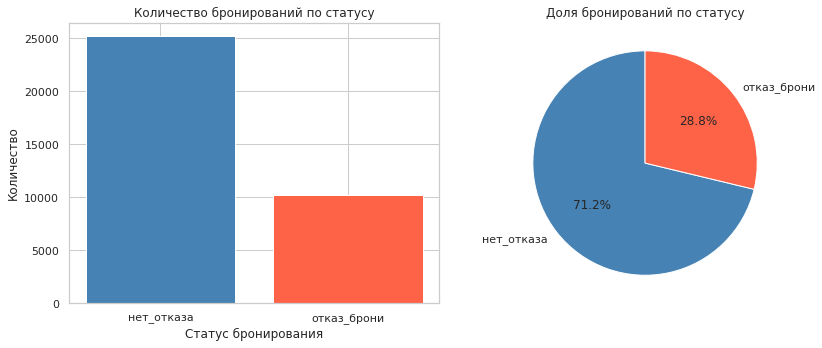

In [7]:
# Распределение целевой переменной
counts = df_bookings['booking_status'].value_counts()
pct    = df_bookings['booking_status'].value_counts(normalize=True).mul(100).round(2)

target_df = pd.DataFrame({'Количество': counts, 'Доля, %': pct})
print('Распределение целевой переменной booking_status:')
display(target_df)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(target_df.index.astype(str), target_df['Количество'],
            color=['steelblue', 'tomato'])
axes[0].set_title('Количество бронирований по статусу')
axes[0].set_ylabel('Количество')
axes[0].set_xlabel('Статус бронирования')

axes[1].pie(
    target_df['Количество'],
    labels=target_df.index.astype(str),
    autopct='%1.1f%%',
    colors=['steelblue', 'tomato'],
    startangle=90
)
axes[1].set_title('Доля бронирований по статусу')

plt.tight_layout()
plt.show()

Наблюдается дисбаланс классов целевой переменной: количество клиентов, не отказавшихся от брони почти в 2.5 раза больше. чем людей отменивших бронь, следует запомнить данный момент и при разделении данных на выборки воспользоваться стратификацией.

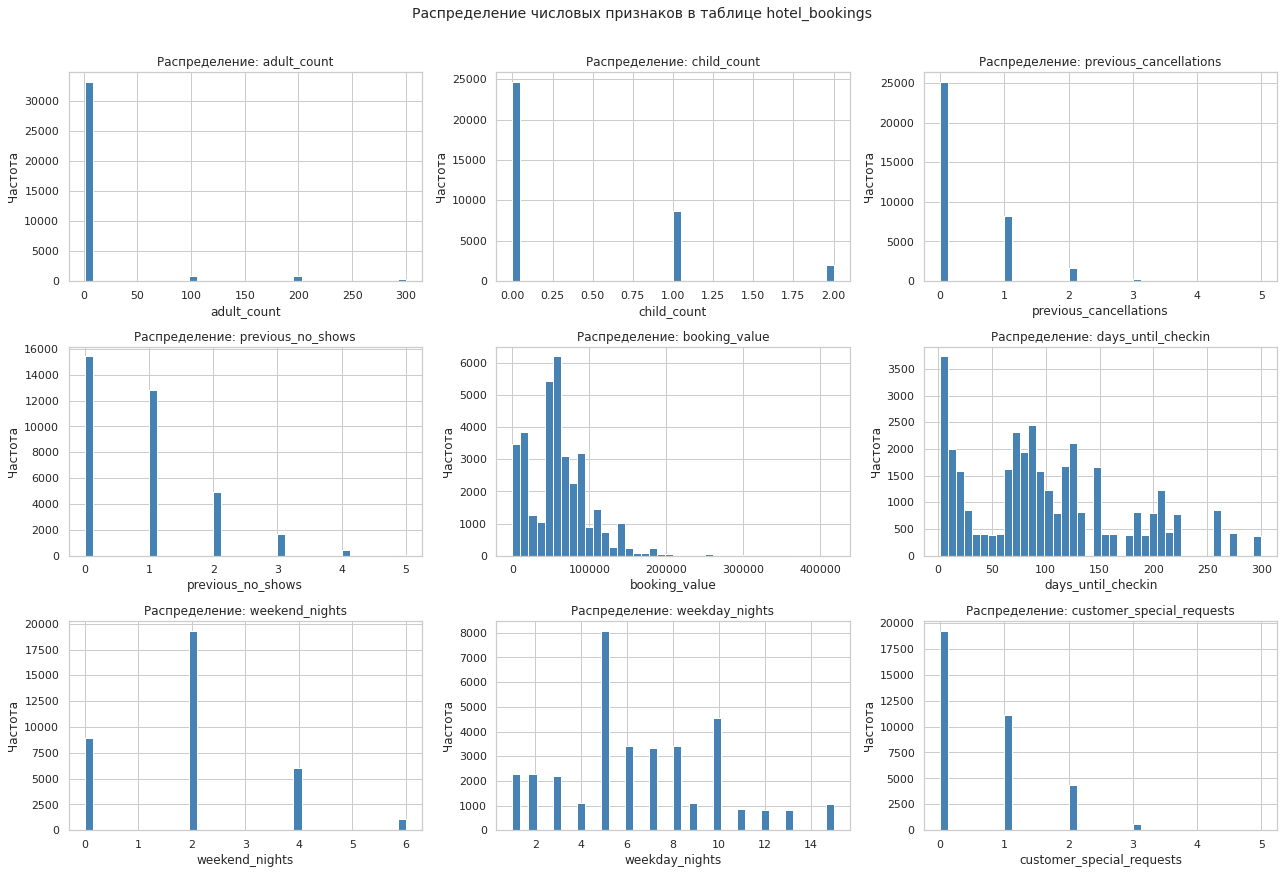

In [8]:
# Числовые признаки таблицы бронирований
num_cols = [
    'adult_count', 'child_count', 'previous_cancellations',
    'previous_no_shows', 'booking_value', 'days_until_checkin',
    'weekend_nights', 'weekday_nights', 'customer_special_requests'
]

n_cols = 3
n_rows = (len(num_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    axes[i].hist(df_bookings[col].dropna(), bins=40,
                 color='steelblue', edgecolor='white')
    axes[i].set_title(f'Распределение: {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Частота')

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Распределение числовых признаков в таблице hotel_bookings',
             fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

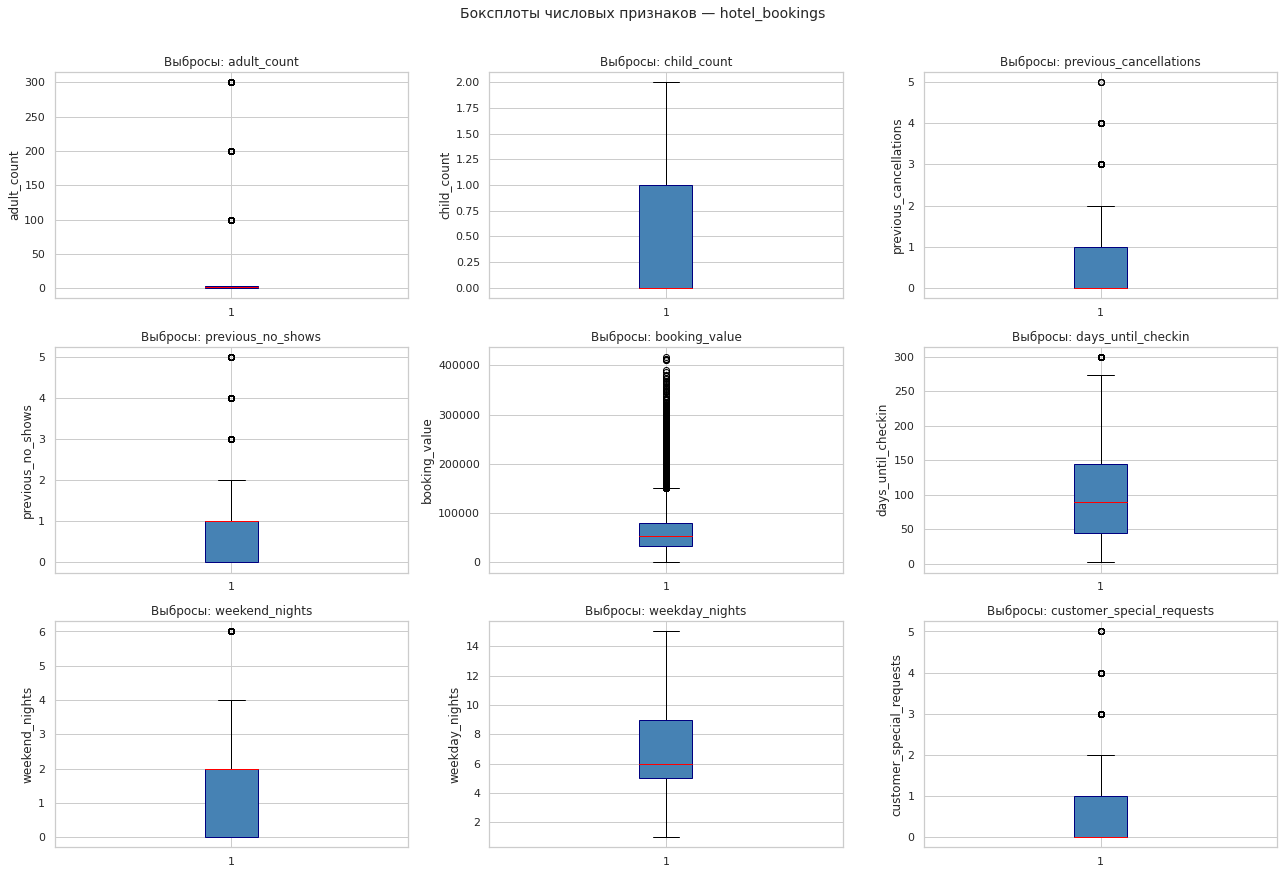

Оценка выбросов по правилу IQR:


,Признак,Выбросов,"Доля, %"
0,adult_count,2151,6.09
3,previous_no_shows,2137,6.05
6,weekend_nights,1082,3.06
4,booking_value,1006,2.85
8,customer_special_requests,706,2.00
5,days_until_checkin,375,1.06
2,previous_cancellations,367,1.04
1,child_count,0,0.00
7,weekday_nights,0,0.00


In [9]:
# Боксплоты
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    axes[i].boxplot(
        df_bookings[col].dropna(), vert=True, patch_artist=True,
        boxprops=dict(facecolor='steelblue', color='navy'),
        medianprops=dict(color='red')
    )
    axes[i].set_title(f'Выбросы: {col}')
    axes[i].set_ylabel(col)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Боксплоты числовых признаков - hotel_bookings',
             fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

# Количественная оценка выбросов по правилу IQR
print('Оценка выбросов по правилу IQR:')
outlier_summary = []
for col in num_cols:
    Q1  = df_bookings[col].quantile(0.25)
    Q3  = df_bookings[col].quantile(0.75)
    IQR = Q3 - Q1
    n_out = ((df_bookings[col] < Q1 - 1.5 * IQR) |
             (df_bookings[col] > Q3 + 1.5 * IQR)).sum()
    outlier_summary.append({
        'Признак':   col,
        'Выбросов':  n_out,
        'Доля, %':   round(n_out / len(df_bookings) * 100, 2)
    })

display(
    pd.DataFrame(outlier_summary).sort_values('Выбросов', ascending=False)
)

Данные с числовыми признаками в большинстве своём не подчиняются законам нормального распределения: есть хвосты справа и явно выраженная ассиметрия. Как следствие - наличие выбросов. Будем пользоваться критерием, что следует обрабоать признаки. в которых процентное содержание выбросов >= 5. Таких признаков всего 2:
- adult_count - количество взрослый гостей;
- previous_no_shows - сколько раз клиент бронировал отель и действительно заселялся.

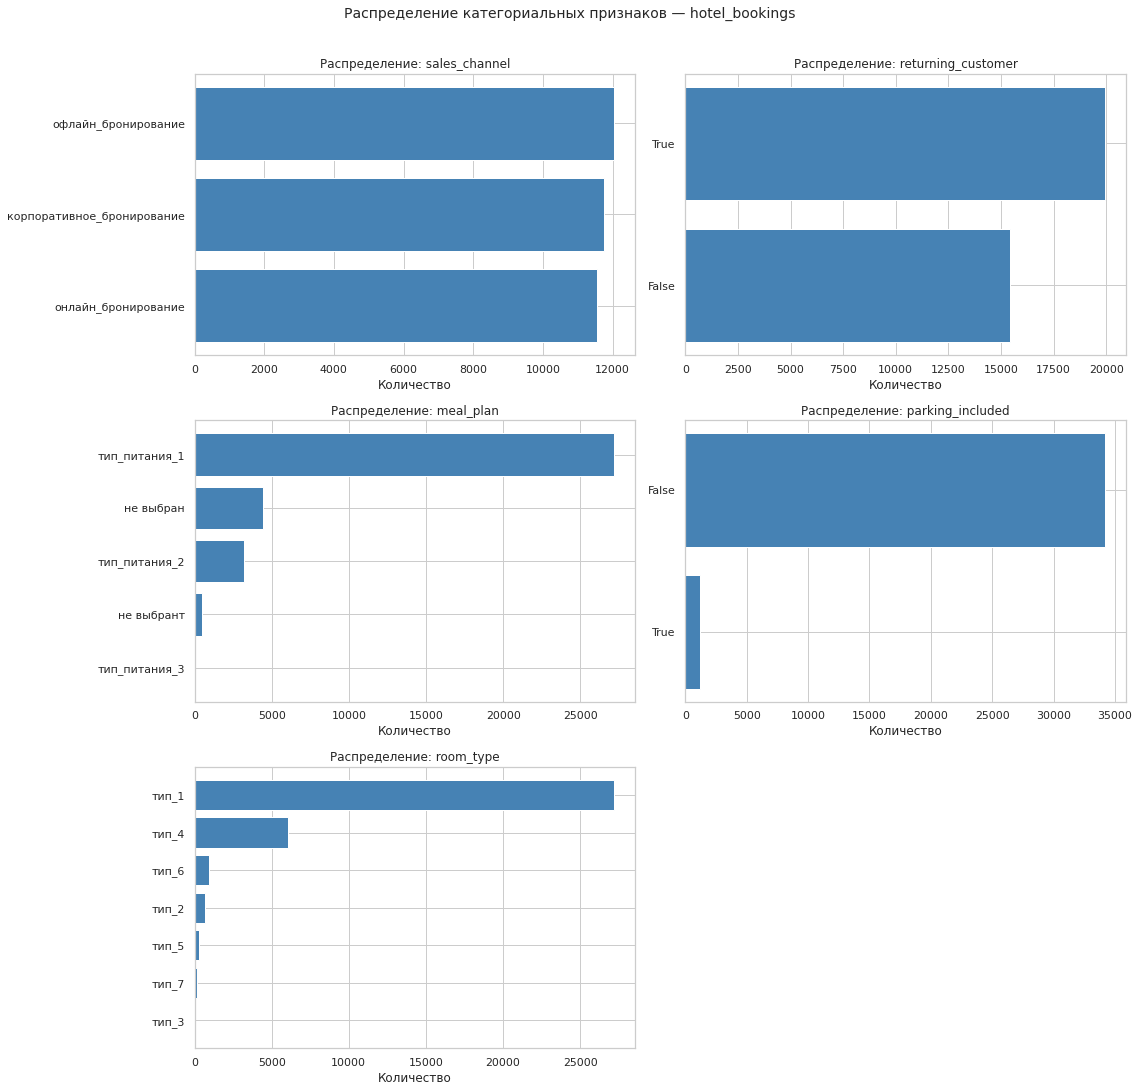

In [10]:
# Категориальные признаки таблицы бронирований
cat_cols = [
    'sales_channel', 'returning_customer',
    'meal_plan', 'parking_included', 'room_type'
]

n_cols = 2
n_rows = (len(cat_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 5))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    vc = df_bookings[col].value_counts()
    axes[i].barh(vc.index.astype(str), vc.values, color='steelblue')
    axes[i].set_title(f'Распределение: {col}')
    axes[i].set_xlabel('Количество')
    axes[i].invert_yaxis()

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Распределение категориальных признаков - hotel_bookings',
             fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

В категориальных данных также пристуствуюет дисбаланс.

**Главные заметки по табилце с бронированиями:**
- Есть полные дубликаты;
- Есть столбцы, с неприемлемым количеством выбросов (adult_count, previous_no_show):

Требуется исправить данные недостатки перед объединением таблиц.

In [11]:
# Удаление дубликатов по booking_id (полные дубликаты строк совпадают с дубликатами по ключу)
before = len(df_bookings)
df_bookings.drop_duplicates(subset='booking_id', keep='first', inplace=True)
df_bookings.reset_index(drop=True, inplace=True)

print(f'Строк до удаления дубликатов:  {before}.')
print(f'Строк после удаления дубликатов: {len(df_bookings)}.')
print(f'Удалено строк: {before - len(df_bookings)}.')

Строк до удаления дубликатов:  35341.
Строк после удаления дубликатов: 30733.
Удалено строк: 4608.


In [12]:
# Обработка выбросов методом winsorization (замена на границы IQR)
# Обрабатываем только признаки с долей выбросов >= 5%
cols_to_clip = ['adult_count', 'previous_no_shows']

for col in cols_to_clip:
    Q1  = df_bookings[col].quantile(0.25)
    Q3  = df_bookings[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    n_before = ((df_bookings[col] < lower) | (df_bookings[col] > upper)).sum()
    df_bookings[col] = df_bookings[col].clip(lower=lower, upper=upper)

    print(f'{col}:')
    print(f'  Границы IQR:       [{lower:.2f}, {upper:.2f}]')
    print(f'  Обработано выбросов: {n_before}')
    print()

print('Обработка выбросов завершена.')
print(f'Итоговый размер hotel_bookings: {df_bookings.shape}.')

adult_count:
  Границы IQR:       [-2.00, 6.00]
  Обработано выбросов: 2151

previous_no_shows:
  Границы IQR:       [-1.50, 2.50]
  Обработано выбросов: 1857

Обработка выбросов завершена.
Итоговый размер hotel_bookings: (30733, 17).


In [13]:
# Обработка аномальных значений booking_value == 0
n_zero_value = (df_bookings['booking_value'] == 0).sum()
pct_zero     = round(n_zero_value / len(df_bookings) * 100, 2)

print(f'Строк с booking_value == 0: {n_zero_value} ({pct_zero}%).')

# Нулевая стоимость бронирования - явная аномалия:
# реальное бронирование не может быть бесплатным.
# Заменяем медианным значением по типу номера,
# чтобы сохранить ценовую дифференциацию между категориями номеров.
median_by_room = df_bookings[df_bookings['booking_value'] > 0].groupby('room_type')['booking_value'].median()

def fill_zero_value(row):
    if row['booking_value'] == 0:
        return median_by_room.get(row['room_type'], df_bookings['booking_value'].median())
    return row['booking_value']

df_bookings['booking_value'] = df_bookings.apply(fill_zero_value, axis=1)

# Проверка
n_zero_after = (df_bookings['booking_value'] == 0).sum()
print(f'Строк с booking_value == 0 после обработки: {n_zero_after}.')
print(f'\nСтатистика booking_value после обработки:')
display(df_bookings['booking_value'].describe())

Строк с booking_value == 0: 1229 (4.0%).
Строк с booking_value == 0 после обработки: 0.

Статистика booking_value после обработки:


count     30733.000000
mean      64090.540487
std       40848.487323
min        6700.000000
25%       46900.000000
50%       60300.000000
75%       80400.000000
max      417221.200000
Name: booking_value, dtype: float64

In [14]:
print('Общая информация о таблице с отзывами')

print(f'\nРазмер таблицы: {df_reviews.shape[0]} строк, {df_reviews.shape[1]} столбцов.')

print('\nТипы данных:')
display(df_reviews.info())

print('\nПервые 5 строк:')
display(df_reviews.head())

print('\nОписательная статистика:')
display(df_reviews.describe(include='all'))

# Пропуски
missing_r = df_reviews.isnull().sum()
missing_r_pct = (missing_r / len(df_reviews) * 100).round(2)

missing_r_df = pd.DataFrame({
    'Пропусков': missing_r,
    'Доля, %':   missing_r_pct
}).sort_values('Пропусков', ascending=False)

print('\nПропуски в таблице отзывов:')
display(missing_r_df)

# Дубликаты
n_dup_r    = df_reviews.duplicated().sum()
n_dup_bid  = df_reviews['booking_id'].duplicated().sum()
n_dup_cid  = df_reviews['customer_id'].duplicated().sum()

print(f'\nПолных дубликатов строк:       {n_dup_r}.')
print(f'Дубликатов по booking_id:      {n_dup_bid}.')
print(f'Дубликатов по customer_id:     {n_dup_cid}.')

Общая информация о таблице с отзывами

Размер таблицы: 25177 строк, 5 столбцов.

Типы данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25177 entries, 0 to 25176
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   customer_id  25177 non-null  object
 1   booking_id   25177 non-null  object
 2   review_date  25177 non-null  object
 3   stay_rating  25177 non-null  int64 
 4   review_text  25177 non-null  object
dtypes: int64(1), object(4)
memory usage: 983.6+ KB


None


Первые 5 строк:


,customer_id,booking_id,review_date,stay_rating,review_text
0,C0001,INN00000,2020-08-21,3,"Неплохо. тихо и спокойно, но отсутствие фена в..."
1,C0001,INN00001,2021-10-15,3,"Неплохо. красивое оформление территории, но не..."
2,C0001,INN00002,2023-03-08,4,Отличный отель! удобные парковочные места. зде...
3,C0002,INN00003,2017-08-13,3,"Неплохо. тёплый приём, но неисправная сантехни..."
4,C0003,INN00004,2019-07-12,4,Отличный отель! качественная косметика в ванно...



Описательная статистика:


,customer_id,booking_id,review_date,stay_rating,review_text
count,25177,25177,25177,25177.000000,25177
unique,13429,21883,2514,NaN,14153
top,C15859,INN26301,2020-06-12,NaN,Отличный отель! хорошие виды из окон.
freq,8,4,29,NaN,42
mean,NaN,NaN,NaN,3.395321,NaN
std,NaN,NaN,NaN,0.541434,NaN
min,NaN,NaN,NaN,2.000000,NaN
25%,NaN,NaN,NaN,3.000000,NaN
50%,NaN,NaN,NaN,3.000000,NaN
75%,NaN,NaN,NaN,4.000000,NaN



Пропуски в таблице отзывов:


,Пропусков,"Доля, %"
customer_id,0,0.0
booking_id,0,0.0
review_date,0,0.0
stay_rating,0,0.0
review_text,0,0.0



Полных дубликатов строк:       0.
Дубликатов по booking_id:      3294.
Дубликатов по customer_id:     11748.


Пропусков в таблице с отзывами нет, однако присутствуют дубликатов по booking_id и customer_id, следует обработать это.

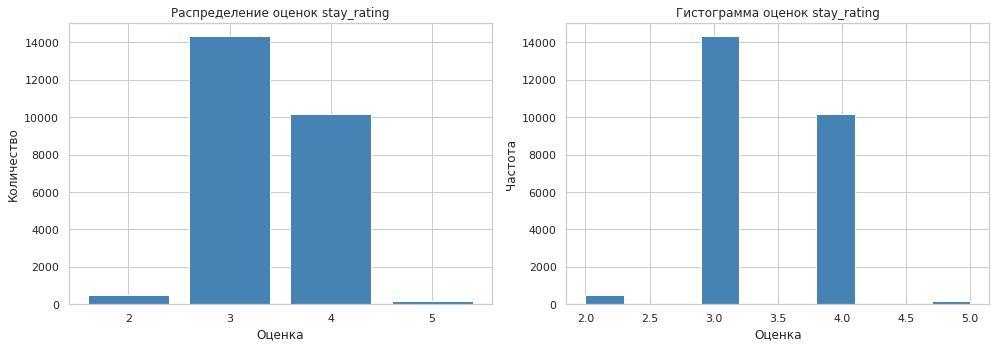

Средняя оценка:   3.40
Медианная оценка: 3.00
Уникальных клиентов в отзывах: 13429
Уникальных бронирований в отзывах: 21883


In [15]:
# Распределение оценок stay_rating
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

vc_rating = df_reviews['stay_rating'].value_counts().sort_index()

axes[0].bar(vc_rating.index.astype(str), vc_rating.values,
            color='steelblue', edgecolor='white')
axes[0].set_title('Распределение оценок stay_rating')
axes[0].set_xlabel('Оценка')
axes[0].set_ylabel('Количество')

df_reviews['stay_rating'].plot(
    kind='hist', bins=10, ax=axes[1],
    color='steelblue', edgecolor='white'
)
axes[1].set_title('Гистограмма оценок stay_rating')
axes[1].set_xlabel('Оценка')
axes[1].set_ylabel('Частота')

plt.tight_layout()
plt.show()

print(f'Средняя оценка:   {df_reviews["stay_rating"].mean():.2f}')
print(f'Медианная оценка: {df_reviews["stay_rating"].median():.2f}')
print(f'Уникальных клиентов в отзывах: {df_reviews["customer_id"].nunique()}')
print(f'Уникальных бронирований в отзывах: {df_reviews["booking_id"].nunique()}')

In [16]:
# Анализ дубликатов по booking_id в таблице отзывов
print('Количество отзывов на одно бронирование:')
display(
    df_reviews.groupby('booking_id')['review_date']
    .count()
    .value_counts()
    .rename_axis('Отзывов на бронь')
    .reset_index(name='Количество броней')
)

print('\nПример бронирований с несколькими отзывами:')
dup_booking_ids = df_reviews[df_reviews.duplicated(subset='booking_id', keep=False)]['booking_id'].unique()
display(df_reviews[df_reviews['booking_id'].isin(dup_booking_ids[:3])].sort_values('booking_id'))

Количество отзывов на одно бронирование:


,Отзывов на бронь,Количество броней
0,1,18858
1,2,2776
2,3,229
3,4,20



Пример бронирований с несколькими отзывами:


,customer_id,booking_id,review_date,stay_rating,review_text
7,C0004,INN00007,2018-02-07,3,"Неплохо. всё супер, но отсутствие парковки. Ко..."
24158,C0004,INN00007,2018-02-20,3,"Неплохо. внимательный персонал, но шумно ночью..."
23,C0017,INN00027,2021-02-03,3,"Неплохо. современные номера, но неудобное расп..."
23670,C0017,INN00027,2021-02-26,3,"Неплохо. тёплый приём, но нет горячей воды по ..."
39,C0031,INN00048,2018-06-28,3,"Неплохо. удобное расположение, но неудобное ра..."
23161,C0031,INN00048,2018-06-26,3,"Неплохо. удобное расположение, но трещины на с..."


In [17]:
# По одному бронированию оставляем последний по дате отзыв -
# он отражает наиболее актуальную обратную связь клиента
before = len(df_reviews)

df_reviews = (
    df_reviews
    .sort_values('review_date', ascending=True)
    .drop_duplicates(subset='booking_id', keep='last')
    .reset_index(drop=True)
)

print(f'Строк до обработки:    {before}.')
print(f'Строк после обработки: {len(df_reviews)}.')
print(f'Удалено строк:         {before - len(df_reviews)}.')

Строк до обработки:    25177.
Строк после обработки: 21883.
Удалено строк:         3294.


In [18]:
# Проверка дат
n_bad_dates = df_reviews['review_date'].isnull().sum()
print(f'Некорректных значений review_date: {n_bad_dates}.')

# Проверка пустых отзывов
n_empty_text = (df_reviews['review_text'].isnull() |
                (df_reviews['review_text'].str.strip() == '')).sum()
print(f'Пустых значений review_text: {n_empty_text}.')

if n_empty_text > 0:
    df_reviews['review_text'] = df_reviews['review_text'].fillna('').str.strip()
    print('Пустые значения review_text заполнены пустой строкой.')

# Проверка диапазона оценок stay_rating (допустимо от 1 до 5)
invalid_rating = df_reviews[~df_reviews['stay_rating'].between(1, 5)]
print(f'\nЗначений stay_rating вне диапазона [1, 5]: {len(invalid_rating)}.')

print(f'\nИтоговый размер hotel_reviews: {df_reviews.shape}.')

Некорректных значений review_date: 0.
Пустых значений review_text: 0.

Значений stay_rating вне диапазона [1, 5]: 0.

Итоговый размер hotel_reviews: (21883, 5).


**Промежуточные выводы:**

**Таблица** hotel_bookings:
- Удалено 4 608 полных дубликатов строк (дублирование по booking_id).
- Пропуски отсутствуют - заполнение не потребовалось.
- Выбросы обработаны методом winsorization по правилу IQR
  для признаков с долей выбросов >= 5%:
    * adult_count       - 2 151 значений (6.09%)
    * previous_no_shows - 2 137 значений (6.05%)

Признаки с долей выбросов < 5% оставлены без изменений,
так как их значения могут отражать реальные случаи бронирования.

**Таблица** hotel_reviews:
- Полных дубликатов строк не обнаружено.
- Дубликаты по booking_id (3 294 строк) обработаны:
  для каждого бронирования оставлен последний по дате отзыв
  как наиболее актуальная обратная связь клиента.
- Дубликаты по customer_id не удалялись - один клиент
  может иметь несколько бронирований и отзывов, это норма.
- Некорректных дат, пустых текстов и аномальных оценок
  не обнаружено.

Выявлена аномалия: 1 229 строк (4.0%) содержали
нулевую стоимость бронирования (`booking_value == 0`). Нулевая цена
является явной ошибкой данных - реальное бронирование не может быть
бесплатным. Нулевые значения заменены медианой по типу номера
(`room_type`), что позволяет сохранить ценовую дифференциацию
между категориями номеров.

После обработки:
- Строк с `booking_value == 0`: 0
- Минимальное значение: 6 700 руб.
- Медиана: 60 300 руб.
- Среднее: 64 091 руб.

Это исправление критично для корректного расчёта признака
`price_per_night` на этапе Feature Engineering.

### Объединение таблиц

In [19]:
# Шаг 1.3. Объединение таблиц

# Убеждаемся, что даты приведены к типу datetime
df_bookings['booking_date'] = pd.to_datetime(df_bookings['booking_date'])
df_reviews['review_date']   = pd.to_datetime(df_reviews['review_date'])

# Определяем столбцы отзывов, которые будем подтягивать
review_cols = ['customer_id', 'booking_id', 'review_date', 'stay_rating', 'review_text']

print('Типы данных ключевых столбцов:')
print(f'  booking_date: {df_bookings["booking_date"].dtype}')
print(f'  review_date:  {df_reviews["review_date"].dtype}')
print(f'\nРазмер df_bookings: {df_bookings.shape}')
print(f'Размер df_reviews:  {df_reviews.shape}')

Типы данных ключевых столбцов:
  booking_date: datetime64[ns]
  review_date:  datetime64[ns]

Размер df_bookings: (30733, 17)
Размер df_reviews:  (21883, 5)


In [20]:
# Объединение выполняется через pd.merge_asof:
# для каждой строки df_bookings находим ближайший предыдущий отзыв
# того же клиента (by='customer_id'), где review_date <= booking_date

# Шаг 1: добавляем customer_id в df_bookings из df_reviews через booking_id
# (связующий ключ между таблицами)
customer_map = df_reviews[['booking_id', 'customer_id']].drop_duplicates(subset='booking_id')
df_bookings = df_bookings.merge(customer_map, on='booking_id', how='left')

print(f'Клиентов найдено в df_bookings: {df_bookings["customer_id"].notna().sum()}')
print(f'Клиентов не найдено (NaN):      {df_bookings["customer_id"].isna().sum()}')

Клиентов найдено в df_bookings: 21883
Клиентов не найдено (NaN):      8850


In [21]:
# Сортировка обязательна для merge_asof
df_bookings_sorted = df_bookings.sort_values('booking_date').reset_index(drop=True)
df_reviews_sorted  = df_reviews.sort_values('review_date').reset_index(drop=True)

# Отзывы: оставляем только нужные столбцы для подтягивания
df_reviews_for_merge = df_reviews_sorted[
    ['customer_id', 'review_date', 'stay_rating', 'review_text']
].copy()

# merge_asof: для каждой booking_date берём ближайший review_date <= booking_date
# в рамках одного customer_id
df_merged = pd.merge_asof(
    df_bookings_sorted,
    df_reviews_for_merge,
    left_on='booking_date',
    right_on='review_date',
    by='customer_id',
    direction='backward'   # ближайшая предыдущая дата
)

print(f'Размер объединённой таблицы: {df_merged.shape}')
print(f'\nПервые строки результата:')
display(df_merged[['booking_id', 'customer_id', 'booking_date',
                    'review_date', 'stay_rating', 'review_text']].head(10))

Размер объединённой таблицы: (30733, 21)

Первые строки результата:


,booking_id,customer_id,booking_date,review_date,stay_rating,review_text
0,INN17387,C9324,2017-01-01,NaT,NaN,NaN
1,INN07784,NaN,2017-01-01,NaT,NaN,NaN
2,INN28926,NaN,2017-01-01,NaT,NaN,NaN
3,INN11824,C6306,2017-01-01,NaT,NaN,NaN
4,INN21754,C11662,2017-01-01,NaT,NaN,NaN
5,INN14477,C7722,2017-01-01,NaT,NaN,NaN
6,INN20018,NaN,2017-01-01,NaT,NaN,NaN
7,INN00177,NaN,2017-01-01,NaT,NaN,NaN
8,INN22445,C12041,2017-01-01,NaT,NaN,NaN
9,INN08256,C4438,2017-01-02,NaT,NaN,NaN


In [22]:
# Доля бронирований, для которых найден отзыв
n_total        = len(df_merged)
n_with_review  = df_merged['stay_rating'].notna().sum()
n_no_review    = df_merged['stay_rating'].isna().sum()

print('Результаты объединения:')
print(f'  Всего бронирований:                    {n_total}')
print(f'  Бронирований с подтянутым отзывом:     {n_with_review} ({n_with_review/n_total*100:.1f}%)')
print(f'  Бронирований без отзыва (новые клиенты или нет предыдущих отзывов): '
      f'{n_no_review} ({n_no_review/n_total*100:.1f}%)')

# Распределение оценок в объединённой таблице
print('\nРаспределение stay_rating в объединённой таблице:')
display(df_merged['stay_rating'].value_counts().sort_index())

# Пример строк с подтянутым отзывом
print('\nПример строк с подтянутым отзывом:')
display(
    df_merged[df_merged['stay_rating'].notna()][
        ['booking_id', 'customer_id', 'booking_date', 'review_date', 'stay_rating', 'review_text']
    ].head(5)
)

# Пример строк без отзыва (новые клиенты)
print('\nПример строк без отзыва:')
display(
    df_merged[df_merged['stay_rating'].isna()][
        ['booking_id', 'customer_id', 'booking_date', 'review_date', 'stay_rating', 'review_text']
    ].head(5)
)

Результаты объединения:
  Всего бронирований:                    30733
  Бронирований с подтянутым отзывом:     8328 (27.1%)
  Бронирований без отзыва (новые клиенты или нет предыдущих отзывов): 22405 (72.9%)

Распределение stay_rating в объединённой таблице:


2.0     178
3.0    4772
4.0    3302
5.0      76
Name: stay_rating, dtype: int64


Пример строк с подтянутым отзывом:


,booking_id,customer_id,booking_date,review_date,stay_rating,review_text
2443,INN02948,C1578,2017-07-09,2017-02-06,2.0,Крайне недоволен. холодная еда в ресторане. за...
2531,INN21823,C11699,2017-07-16,2017-05-06,4.0,Отличный отель! всё супер. лучший отель в этом...
2560,INN24083,C12923,2017-07-18,2017-02-20,4.0,Отличный отель! отличная шумоизоляция. здесь ц...
2672,INN09253,C4967,2017-07-26,2017-05-06,4.0,Отличный отель! удобные парковочные места. буд...
2697,INN01691,C0933,2017-07-28,2017-03-05,4.0,Отличный отель! спа‑услуги на отлично. здесь к...



Пример строк без отзыва:


,booking_id,customer_id,booking_date,review_date,stay_rating,review_text
0,INN17387,C9324,2017-01-01,NaT,NaN,NaN
1,INN07784,NaN,2017-01-01,NaT,NaN,NaN
2,INN28926,NaN,2017-01-01,NaT,NaN,NaN
3,INN11824,C6306,2017-01-01,NaT,NaN,NaN
4,INN21754,C11662,2017-01-01,NaT,NaN,NaN


In [23]:
# Заполняем только review_text - необходимо до векторизации
# stay_rating и прочие числовые пропуски - через SimpleImputer в пайплайне

df_merged['review_text'] = df_merged['review_text'].fillna('')

print(f'Пропуски review_text: {df_merged["review_text"].isna().sum()}.')
print(f'Пропуски stay_rating: {df_merged["stay_rating"].isna().sum()} - будут обработаны в пайплайне.')
print(f'\nИтоговый размер df_merged: {df_merged.shape}.')

Пропуски review_text: 0.
Пропуски stay_rating: 22405 - будут обработаны в пайплайне.

Итоговый размер df_merged: (30733, 21).


**Промежуточные выводы**

Таблицы `hotel_bookings` и `hotel_reviews` объединены с помощью `pd.merge_asof`
по следующему правилу: для каждой даты бронирования (`booking_date`) подтягивается
ближайший предыдущий отзыв клиента (`review_date <= booking_date`) в рамках
одного `customer_id`.

**Результаты объединения:**

| Показатель | Значение |
|---|---|
| Итоговый размер таблицы | 30 733 строки, 21 столбец |
| Бронирований с подтянутым отзывом | 8 328 (27.1%) |
| Бронирований без отзыва | 22 405 (72.9%) |

**Причины отсутствия отзывов (72.9%):**

- Часть клиентов отсутствует в таблице `hotel_reviews` - новые клиенты,
  которые ещё не оставляли отзывов (`customer_id = NaN`).
- Часть клиентов присутствует в таблице отзывов, однако все их отзывы датированы
  позже текущей даты бронирования - то есть на момент бронирования предыдущего
  отзыва не существовало.

**Распределение оценок `stay_rating` среди подтянутых отзывов:**

| Оценка | Количество |
|---|---|
| 2.0 | 178 |
| 3.0 | 4 772 |
| 4.0 | 3 302 |
| 5.0 | 76 |

Оценка 1.0 в данных отсутствует. Преобладают оценки 3.0 и 4.0,
что свидетельствует об умеренной удовлетворённости клиентов.

**Обработка пропусков:**

- `review_text`: заполнен пустой строкой на данном этапе -
  это необходимо для корректной последующей векторизации текста (`TfidfVectorizer`).
- `stay_rating`: 22 405 пропущенных значений будут обработаны через
  `SimpleImputer` в пайплайне модели. Такой подход исключает утечку данных:
  импьютер обучается исключительно на тренировочной выборке и применяется
  к валидационной и тестовой.

In [24]:
# Верификация корректности merge_asof

# 1. Главное правило: review_date должна быть строго <= booking_date
violations = df_merged[
    df_merged['review_date'].notna() &
    (df_merged['review_date'] > df_merged['booking_date'])
]
print(f'Нарушений правила review_date <= booking_date: {len(violations)}.')

# 2. Проверка: для каждой строки с отзывом убеждаемся,
#    что подтянут именно ближайший предыдущий отзыв, а не произвольный
# Берём случайную выборку из 5 строк с подтянутым отзывом и проверяем вручную
sample = df_merged[df_merged['review_date'].notna()].sample(5, random_state=RANDOM_STATE)

print('\nРучная проверка - случайная выборка строк с отзывом:')
for _, row in sample.iterrows():
    cid  = row['customer_id']
    bdate = row['booking_date']
    rdate = row['review_date']

    # Все отзывы этого клиента до даты бронирования
    candidate_reviews = df_reviews[
        (df_reviews['customer_id'] == cid) &
        (df_reviews['review_date'] <= bdate)
    ].sort_values('review_date', ascending=False)

    # Ближайший должен совпадать с подтянутым
    if len(candidate_reviews) > 0:
        expected_date = candidate_reviews.iloc[0]['review_date']
        match = expected_date == rdate
    else:
        expected_date = None
        match = False

    print(f'  booking_id={row["booking_id"]} | booking_date={bdate.date()} | '
          f'review_date={rdate.date()} | ожидалось={expected_date} | '
          f'корректно={match}')

# 3. Проверка: нет ли задвоений строк после объединения
print(f'\nСтрок в df_bookings до объединения:  {df_bookings_sorted.shape[0]}.')
print(f'Строк в df_merged после объединения: {df_merged.shape[0]}.')
print(f'Количество строк сохранилось: {df_bookings_sorted.shape[0] == df_merged.shape[0]}.')

# 4. Проверка: дубликатов по booking_id в итоговой таблице нет
n_dup_merged = df_merged['booking_id'].duplicated().sum()
print(f'\nДубликатов по booking_id в df_merged: {n_dup_merged}.')

Нарушений правила review_date <= booking_date: 0.

Ручная проверка - случайная выборка строк с отзывом:
  booking_id=INN14464 | booking_date=2020-02-20 | review_date=2019-08-26 | ожидалось=2019-08-26 00:00:00 | корректно=True
  booking_id=INN09358 | booking_date=2019-02-08 | review_date=2017-12-16 | ожидалось=2017-12-16 00:00:00 | корректно=True
  booking_id=INN04524 | booking_date=2023-03-30 | review_date=2022-09-14 | ожидалось=2022-09-14 00:00:00 | корректно=True
  booking_id=INN23206 | booking_date=2019-10-16 | review_date=2019-03-14 | ожидалось=2019-03-14 00:00:00 | корректно=True
  booking_id=INN09520 | booking_date=2021-02-08 | review_date=2020-01-31 | ожидалось=2020-01-31 00:00:00 | корректно=True

Строк в df_bookings до объединения:  30733.
Строк в df_merged после объединения: 30733.
Количество строк сохранилось: True.

Дубликатов по booking_id в df_merged: 0.


Также была проведена комплексная проверка после объединения данных:

- Проверка 1. Что нет данных об отзывах из будущего
- Проверка 2. Что подтянут именно ближайших предыдущий отзыв
- Проверка 3. Корректность работы merge_asof, не были ли размножены строки
- Проверка 4. Нет дубликатов об информации с бронированием

Все проверки пройдены успешно, таблицы объединены, переходим к этапу разработки новых признаков.

### Создание новых признаков

**Признаки на основе данных о бронировании**

In [25]:
# Приводим даты к datetime
df_merged['booking_date'] = pd.to_datetime(df_merged['booking_date'])

# 1. Сезонность - месяц и сезон оформления брони
df_merged['booking_month'] = df_merged['booking_date'].dt.month

def get_season(month):
    if month in [12, 1, 2]:
        return 'winter'
    elif month in [3, 4, 5]:
        return 'spring'
    elif month in [6, 7, 8]:
        return 'summer'
    else:
        return 'autumn'

df_merged['season'] = df_merged['booking_month'].apply(get_season)

# 2. Лояльность клиента
# Повторный клиент с историей успешных заездов и без отмен - более надёжный
df_merged['loyalty_score'] = (
      df_merged['returning_customer'] * 2   # вес за статус повторного клиента
    + df_merged['previous_no_shows']        # успешные заезды в прошлом
    - df_merged['previous_cancellations']   # штраф за прошлые отмены
)

# 3. Общая длительность пребывания (ночей)
df_merged['total_nights'] = (
    df_merged['weekend_nights'] + df_merged['weekday_nights']
)

# 4. Стоимость за ночь - нормализованный ценовой показатель
df_merged['price_per_night'] = (
    df_merged['booking_value'] / df_merged['total_nights'].replace(0, np.nan)
)

# 5. Признак раннего бронирования (более 90 дней до заезда)
# Ранние брони чаще отменяются из-за неопределённости планов
df_merged['is_early_booking'] = (
    df_merged['days_until_checkin'] > 90
).astype(int)

# 7. Флаг наличия предыдущего отзыва
df_merged['has_review'] = (
    df_merged['review_text'] != ''
).astype(int)

new_features = [
    'booking_month', 'season', 'loyalty_score', 'total_nights',
    'price_per_night', 'is_early_booking', 'has_review'
]

print('Описательная статистика новых признаков:')
display(df_merged[new_features].describe(include='all'))

Описательная статистика новых признаков:


,booking_month,season,loyalty_score,total_nights,price_per_night,is_early_booking,has_review
count,30733.000000,30733,30733.000000,30733.000000,30733.000000,30733.000000,30733.000000
unique,NaN,4,NaN,NaN,NaN,NaN,NaN
top,NaN,summer,NaN,NaN,NaN,NaN,NaN
freq,NaN,7780,NaN,NaN,NaN,NaN,NaN
mean,6.521003,NaN,1.564035,8.491459,7759.950445,0.487977,0.270979
std,3.442929,NaN,1.700655,4.719349,3686.048992,0.499864,0.444473
min,1.000000,NaN,-4.000000,1.000000,2871.428571,0.000000,0.000000
25%,4.000000,NaN,0.000000,5.000000,6700.000000,0.000000,0.000000
50%,7.000000,NaN,2.000000,8.000000,6700.000000,0.000000,0.000000
75%,10.000000,NaN,3.000000,11.000000,6700.000000,1.000000,1.000000


**Признаки на основе текстов отзывов (TF-IDF)**

Векторизация будет производиться внутри пайплайна каждой модели дабы избежать утечки данных.

In [26]:
# Проверка итогового состава новых признаков
print('Итоговый состав df_merged после Feature Engineering:')
print(f'  Строк:    {df_merged.shape[0]}')
print(f'  Столбцов: {df_merged.shape[1]}')

print('\nСписок новых признаков:')
for f in new_features:
    print(f'  {f}: {df_merged[f].dtype}')

# Проверяем что TF-IDF столбцов нет
tfidf_cols = [col for col in df_merged.columns if col.startswith('tfidf_')]
print(f'\nTF-IDF столбцов в df_merged: {len(tfidf_cols)} - векторизация будет выполнена после сплита.')

Итоговый состав df_merged после Feature Engineering:
  Строк:    30733
  Столбцов: 28

Список новых признаков:
  booking_month: int64
  season: object
  loyalty_score: float64
  total_nights: int64
  price_per_night: float64
  is_early_booking: int64
  has_review: int64

TF-IDF столбцов в df_merged: 0 - векторизация будет выполнена после сплита.


**Признаки на основе данных о брони**

Создано 7 новых признаков:

| Признак | Логика создания |
|---|---|
| `booking_month` | Месяц оформления брони - учитывает сезонные паттерны спроса |
| `season` | Сезон: зима / весна / лето / осень на основе месяца бронирования |
| `loyalty_score` | Лояльность клиента: повторный статус (вес x2) + успешные заезды - отмены. Диапазон: от -4.0 до 4.5 |
| `total_nights` | Суммарная длительность пребывания (weekday + weekend ночей). Медиана - 8 ночей |
| `price_per_night` | Стоимость бронирования за одну ночь - нормализованный ценовой показатель. Медиана - 6 700 руб. |
| `is_early_booking` | Флаг раннего бронирования (более 90 дней до заезда) - 48.8% бронирований |
| `has_review` | Флаг наличия предыдущего отзыва клиента - 27.1% бронирований |

Признак `is_weekend_stay` удалён на этапе проверки - нулевая дисперсия
(все значения равны 0), признак не несёт информации для модели.

**Признаки на основе текстов отзывов (TF-IDF)**

Будут созданы внутри пайплайна для каждой модели.

**Итог**

Итоговая таблица `df_merged` содержит **30 733 строки** и **28 столбцов**,
из которых 7 - инженерные признаки на основе брони.

### Анализ итоговой таблицы

In [28]:
# Анализ итоговой таблицы перед моделированием
print('Анализ итоговой таблицы')

print(f'\nРазмер таблицы: {df_merged.shape[0]} строк, {df_merged.shape[1]} столбцов.')

n_num = df_merged.select_dtypes(include=['int64', 'float64']).shape[1]
n_cat = df_merged.select_dtypes(include='object').shape[1]
n_dt  = df_merged.select_dtypes(include='datetime64').shape[1]
print(f'\nЧисловых столбцов:       {n_num}')
print(f'Категориальных столбцов: {n_cat}')
print(f'Столбцов с датами:       {n_dt}')

missing = df_merged.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(f'\nСтолбцов с пропусками: {len(missing)}')
if len(missing) > 0:
    display(pd.DataFrame({
        'Пропусков': missing,
        'Доля, %':   (missing / len(df_merged) * 100).round(2)
    }))

Анализ итоговой таблицы

Размер таблицы: 30733 строк, 28 столбцов.

Числовых столбцов:       16
Категориальных столбцов: 8
Столбцов с датами:       2

Столбцов с пропусками: 3


,Пропусков,"Доля, %"
review_date,22405,72.9
stay_rating,22405,72.9
customer_id,8850,28.8


Уникальные значения booking_status:
['нет_отказа' 'отказ_брони']

Распределение target:


,Количество,"Доля, %"
0,21883,71.2
1,8850,28.8


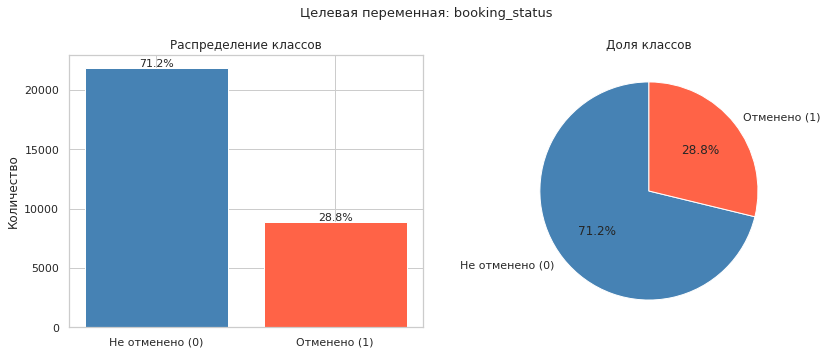

In [29]:
# Бинаризация целевой переменной
print('Уникальные значения booking_status:')
print(df_merged['booking_status'].unique())

df_merged['target'] = (df_merged['booking_status'] == 'отказ_брони').astype(int)

counts = df_merged['target'].value_counts().sort_index()
pcts   = df_merged['target'].value_counts(normalize=True).sort_index().mul(100).round(2)

print('\nРаспределение target:')
display(pd.DataFrame({'Количество': counts, 'Доля, %': pcts}))

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
labels = ['Не отменено (0)', 'Отменено (1)']

axes[0].bar(labels, counts.values, color=['steelblue', 'tomato'])
axes[0].set_title('Распределение классов')
axes[0].set_ylabel('Количество')
for i, (v, p) in enumerate(zip(counts.values, pcts.values)):
    axes[0].text(i, v + 100, f'{p}%', ha='center', fontsize=11)

axes[1].pie(
    counts.values, labels=labels, autopct='%1.1f%%',
    colors=['steelblue', 'tomato'], startangle=90
)
axes[1].set_title('Доля классов')

plt.suptitle('Целевая переменная: booking_status', fontsize=13)
plt.tight_layout()
plt.show()

In [30]:
# Определяем признаки для моделирования
drop_cols = [
    'booking_id',      # идентификатор
    'customer_id',     # идентификатор клиента
    'booking_date',    # дата - извлечены booking_month и season
    'review_date',     # дата - использована при merge_asof
    'review_text',     # текст - векторизация будет выполнена в пайплайне модели
    'booking_status',  # источник целевой переменной
    'target'           # целевая переменная
]

feature_cols = [col for col in df_merged.columns if col not in drop_cols]
cat_features = df_merged[feature_cols].select_dtypes(include='object').columns.tolist()
num_features = df_merged[feature_cols].select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

X = df_merged[feature_cols].copy()
y = df_merged['target'].copy()

print(f'Всего признаков для модели: {len(feature_cols)}')
print(f'  Числовых:       {len(num_features)}')
print(f'  Категориальных: {len(cat_features)}')
print(f'\nКатегориальные признаки: {cat_features}')
print(f'\nПримечание: review_text исключён из feature_cols.')
print(f'Векторизация TF-IDF будет выполнена в пайплайне модели')
print(f'после разбивки данных во избежание утечки данных.')

Всего признаков для модели: 22
  Числовых:       16
  Категориальных: 4

Категориальные признаки: ['sales_channel', 'meal_plan', 'room_type', 'season']

Примечание: review_text исключён из feature_cols.
Векторизация TF-IDF будет выполнена в пайплайне модели
после разбивки данных во избежание утечки данных.


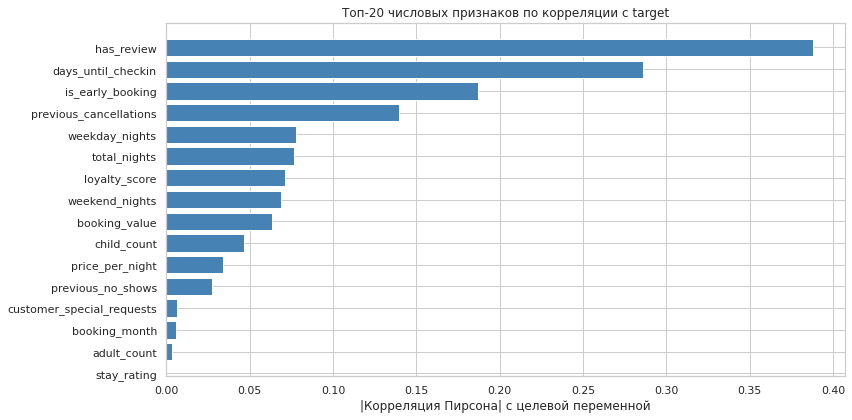

Топ-10 признаков по корреляции с целевой переменной:


,Признак,|Корреляция|
0,has_review,0.387718
1,days_until_checkin,0.286024
2,is_early_booking,0.186943
3,previous_cancellations,0.139438
4,weekday_nights,0.077987
5,total_nights,0.076687
6,loyalty_score,0.071038
7,weekend_nights,0.068906
8,booking_value,0.063229
9,child_count,0.046547


In [31]:
# Корреляция числовых признаков с целевой переменной
corr_with_target = (
    df_merged[num_features + ['target']]
    .corr()['target']
    .drop('target')
    .abs()
    .sort_values(ascending=False)
    .head(20)
)

plt.figure(figsize=(12, 6))
plt.barh(corr_with_target.index[::-1], corr_with_target.values[::-1],
         color='steelblue')
plt.xlabel('|Корреляция Пирсона| с целевой переменной')
plt.title('Топ-20 числовых признаков по корреляции с target')
plt.tight_layout()
plt.show()

print('Топ-10 признаков по корреляции с целевой переменной:')
display(
    corr_with_target.head(10)
    .reset_index()
    .rename(columns={'index': 'Признак', 'target': '|Корреляция|'})
)

**Анализ итоговой таблицы**

**Состав данных**

- Итоговая таблица содержит **30 733 строки** и **28 столбцов**.
- Для обучения отобраны **22 признака** за исключением идентификаторов
  (`booking_id`, `customer_id`), исходных дат (`booking_date`, `review_date`),
  текста отзыва (`review_text`) и целевой переменной (`booking_status`).
- Текст отзыва `review_text` не удалён из данных - векторизация TF-IDF
  будет выполнена в пайплайне модели после разбивки на выборки
  во избежание утечки данных.

**Целевая переменная**

| Класс | Количество | Доля |
|---|---|---|
| 0 - не отменено | 21 883 | 71.2% |
| 1 - отменено | 8 850 | 28.8% |

Присутствует умеренный дисбаланс классов (соотношение ~2.5:1).
При обучении моделей будет учитываться балансировка классов.

**Пропуски**

Столбцов с пропусками: 3.

| Признак | Пропусков | Доля, % |
|---|---|---|
| `review_date` | 22 405 | 72.9% |
| `stay_rating` | 22 405 | 72.9% |
| `customer_id` | 8 850 | 28.8% |

`review_date` и `customer_id` исключены из признаков - пропуски
в них не влияют на обучение. `stay_rating` входит в признаки -
пропуски будут обработаны через `SimpleImputer(strategy='median')`
в пайплайне модели, что исключает утечку данных.

**Корреляция числовых признаков с целевой переменной**

Топ-10 наиболее значимых признаков по |корреляции Пирсона|:

| Признак | Корреляция | Интерпретация |
|---|---|---|
| `has_review` | 0.388 | Наличие предыдущего отзыва - сильнейший сигнал |
| `days_until_checkin` | 0.286 | Чем дальше заезд, тем выше риск отмены |
| `is_early_booking` | 0.187 | Раннее бронирование повышает риск отмены |
| `previous_cancellations` | 0.139 | История отмен повышает риск новой отмены |
| `weekday_nights` | 0.078 | Больше будних ночей - ниже риск отмены |
| `total_nights` | 0.077 | Длительность пребывания влияет на риск |
| `loyalty_score` | 0.071 | Высокая лояльность снижает риск отмены |
| `weekend_nights` | 0.069 | Выходные ночи связаны с риском отмены |
| `booking_value` | 0.063 | Стоимость бронирования влияет на риск |
| `child_count` | 0.047 | Наличие детей повышает риск отмены |

Все корреляции умеренные (< 0.4) - линейных зависимостей нет,
что типично для задач классификации. TF-IDF признаки в корреляционном
анализе не участвуют, так как векторизация перенесена в пайплайн.
Ансамблевые методы (градиентный бустинг, случайный лес) способны
выявить нелинейные зависимости между признаками и целевой переменной.

**Вывод**

Данные подготовлены к моделированию. Ключевые особенности,
которые необходимо учесть на этапе 2:

- умеренный дисбаланс классов (71.2% / 28.8%) - балансировка при обучении;
- 72.9% пропусков в `stay_rating` - импьютация медианой в пайплайне;
- 4 категориальных признака (`sales_channel`, `meal_plan`, `room_type`,
  `season`) - кодирование в пайплайне;
- TF-IDF векторизация `review_text` - выполняется в пайплайне модели
  после разбивки данных;
- метрика оптимизации - **Incremental Revenue**.

## Этап 2: моделирование

### Обучение и оптимизация модели

На этапе моделирования будут обучены следующие базовые модели:

- CatBoost:
- Random Forest.

Проведем подбор оптимальных гиперпараметров по ключевой экономической метрике Incremental Revenue и выберем наилучшую модель. Обработка категориальных данных будет реализована следующим образом:

- CatBoost: через встроенные методы;
- Random Forest: будет создан пайплайн с предварительной обработкой категориальных признаков при помощи OrdinalEncoder.

Исходные данные будут разделены по следующему принципу:

- Обучающая выборка 60% данных;
- Калибровочная выборка 20% данных;
- Тестовая выборка 20% данных.

In [37]:
# Удаляем неинформативные признаки
# review_text оставляем - векторизация выполняется в пайплайне модели
drop_cols = [
    'booking_id',      # идентификатор
    'customer_id',     # идентификатор
    'booking_date',    # дата - извлечены booking_month и season
    'review_date',     # дата - использована при merge_asof
    'booking_status',  # источник целевой переменной - утечка данных
    'target'           # целевая переменная, не признак
]

# Сортируем по дате бронирования - обязательно для временных данных
df_merged_sorted = df_merged.sort_values('booking_date').reset_index(drop=True)

feature_cols  = [col for col in df_merged_sorted.columns if col not in drop_cols]
num_features  = df_merged_sorted[feature_cols].select_dtypes(
    include=['int64', 'float64']
).columns.tolist()
text_feature  = 'review_text'
cat_features  = [
    col for col in df_merged_sorted[feature_cols]
    .select_dtypes(include='object').columns.tolist()
    if col != text_feature
]

X = df_merged_sorted[feature_cols].copy()
y = df_merged_sorted['target'].copy()

print(f'Признаков для модели: {len(feature_cols)}')
print(f'  Числовых:           {len(num_features)}')
print(f'  Категориальных:     {len(cat_features)} - {cat_features}')
print(f'  Текстовых:          1 - {text_feature}')
print(f'\nРазмер X: {X.shape}')
print(f'Распределение y:\n{y.value_counts()}')

# Хронологический сплит через iloc
n_total    = len(X)
n_train    = int(n_total * 0.60)
n_trainval = int(n_total * 0.80)

X_train    = X.iloc[:n_train]
y_train    = y.iloc[:n_train]
X_calib    = X.iloc[n_train:n_trainval]
y_calib    = y.iloc[n_train:n_trainval]
X_test     = X.iloc[n_trainval:]
y_test     = y.iloc[n_trainval:]
X_trainval = X.iloc[:n_trainval]
y_trainval = y.iloc[:n_trainval]

print('Хронологический сплит:')
print(f'  Обучающая:     {len(X_train)} ({len(X_train)/n_total*100:.1f}%) '
      f'| {df_merged_sorted["booking_date"].iloc[0].date()} - '
      f'{df_merged_sorted["booking_date"].iloc[n_train-1].date()}')
print(f'  Калибровочная: {len(X_calib)} ({len(X_calib)/n_total*100:.1f}%) '
      f'| {df_merged_sorted["booking_date"].iloc[n_train].date()} - '
      f'{df_merged_sorted["booking_date"].iloc[n_trainval-1].date()}')
print(f'  Тестовая:      {len(X_test)} ({len(X_test)/n_total*100:.1f}%) '
      f'| {df_merged_sorted["booking_date"].iloc[n_trainval].date()} - '
      f'{df_merged_sorted["booking_date"].iloc[-1].date()}')

print(f'\nРаспределение y_train:\n{y_train.value_counts()}')
print(f'\nРаспределение y_calib:\n{y_calib.value_counts()}')
print(f'\nРаспределение y_test:\n{y_test.value_counts()}')

Признаков для модели: 23
  Числовых:           16
  Категориальных:     4 - ['sales_channel', 'meal_plan', 'room_type', 'season']
  Текстовых:          1 - review_text

Размер X: (30733, 23)
Распределение y:
0    21883
1     8850
Name: target, dtype: int64
Хронологический сплит:
  Обучающая:     18439 (60.0%) | 2017-01-01 - 2019-11-30
  Калибровочная: 6147 (20.0%) | 2019-11-30 - 2020-09-20
  Тестовая:      6147 (20.0%) | 2020-09-20 - 2025-10-22

Распределение y_train:
0    12994
1     5445
Name: target, dtype: int64

Распределение y_calib:
0    4316
1    1831
Name: target, dtype: int64

Распределение y_test:
0    4573
1    1574
Name: target, dtype: int64


In [38]:
# Функция для расчёта Incremental Revenue
def calc_ir(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    total_cancellations = int(y_true.sum())
    total_success = int((y_true == 0).sum())

    ir_before = (total_success * AVG_REV) - (total_cancellations * LOST_REV)

    ir_after = (tp * PER_REBOOKING + tn * AVG_REV - fp * COST_FP - fn * LOST_REV)

    ir = ir_after - ir_before

    return ir

# Проверка функции на тестовых данных
test_true = np.array([0, 0, 1, 1, 0, 1])
test_pred = np.array([0, 0, 1, 0, 1, 1])
print(f'Проверка calc_ir: {calc_ir(test_true, test_pred):,.0f} руб.')

Проверка calc_ir: 147,500 руб.


In [39]:
# Кросс-валидация с учётом временного порядка
# test_size=2000 - размер валидационной выборки на каждом фолде
def cross_val_ir(model, X, y, n_splits=CV, val_size=VAL_SIZE):
    tss    = TimeSeriesSplit(n_splits=n_splits, test_size=val_size)
    scores = []

    X_arr = X.values if hasattr(X, 'values') else X
    y_arr = y.values if hasattr(y, 'values') else y

    for fold, (train_idx, val_idx) in enumerate(tss.split(X_arr)):
        X_tr  = X.iloc[train_idx] if hasattr(X, 'iloc') else X_arr[train_idx]
        X_val = X.iloc[val_idx]   if hasattr(X, 'iloc') else X_arr[val_idx]
        y_tr  = y.iloc[train_idx] if hasattr(y, 'iloc') else y_arr[train_idx]
        y_val = y.iloc[val_idx]   if hasattr(y, 'iloc') else y_arr[val_idx]

        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        ir     = calc_ir(y_val, y_pred)
        scores.append(ir)
        print(f'  Фолд {fold+1}: train={len(train_idx)}, val={len(val_idx)}, IR={ir:,.0f} руб.')

    return np.array(scores)

# Проверка фолдов на X_train
print('Структура фолдов TimeSeriesSplit:')
tss_check = TimeSeriesSplit(n_splits=CV, test_size=VAL_SIZE)
for fold, (tr_idx, val_idx) in enumerate(tss_check.split(X_train)):
    print(f'  Фолд {fold+1}: train={len(tr_idx)}, val={len(val_idx)}')

Структура фолдов TimeSeriesSplit:
  Фолд 1: train=12439, val=2000
  Фолд 2: train=14439, val=2000
  Фолд 3: train=16439, val=2000


In [41]:
# Задаём список русских стоп-слов
russian_stopwords = [
    'и', 'в', 'во', 'не', 'что', 'он', 'на', 'я', 'с', 'со', 'как',
    'а', 'то', 'все', 'она', 'так', 'его', 'но', 'да', 'ты', 'к',
    'у', 'же', 'вы', 'за', 'бы', 'по', 'только', 'её', 'мне', 'было',
    'вот', 'от', 'меня', 'ещё', 'нет', 'о', 'из', 'ему', 'теперь',
    'когда', 'даже', 'ну', 'вдруг', 'ли', 'если', 'уже', 'или', 'ни',
    'быть', 'был', 'него', 'до', 'вас', 'нибудь', 'опять', 'уж', 'вам',
    'ведь', 'там', 'потом', 'себя', 'ничего', 'ей', 'может', 'они',
    'тут', 'где', 'есть', 'надо', 'ней', 'для', 'мы', 'тебя', 'их',
    'чем', 'была', 'сам', 'чтоб', 'без', 'будто', 'человек', 'чего',
    'раз', 'тоже', 'себе', 'под', 'будет', 'ж', 'тогда', 'кто', 'этот',
    'того', 'потому', 'этого', 'какой', 'совсем', 'ним', 'здесь', 'эту',
    'им', 'два', 'об', 'другой', 'хоть', 'после', 'над', 'больше',
    'тот', 'через', 'эти', 'нас', 'про', 'всего', 'них', 'какая', 'много'
]

In [42]:
N_TFIDF = 50

rf_preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler',  StandardScaler())
    ]), num_features),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(
            handle_unknown='use_encoded_value',
            unknown_value=-1
        ))
    ]), cat_features),
    ('tfidf', TfidfVectorizer(
        max_features=N_TFIDF,
        min_df=5,
        max_df=0.95,
        ngram_range=(1, 2),
        sublinear_tf=True,
        stop_words=russian_stopwords
    ), text_feature)
])

def get_rf_pipeline(params):
    return Pipeline([
        ('preprocessor', rf_preprocessor),
        ('model', RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1,
            **params
        ))
    ])

def objective_rf(trial):
    params = {
        'n_estimators':      trial.suggest_int('n_estimators', 100, 500),
        'max_depth':         trial.suggest_int('max_depth', 3, 15),
        'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
        'min_samples_leaf':  trial.suggest_int('min_samples_leaf', 1, 10),
        'max_features':      trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.5]),
        'class_weight':      trial.suggest_categorical('class_weight', ['balanced', None])
    }
    pipeline = get_rf_pipeline(params)
    scores   = cross_val_ir(pipeline, X_train, y_train)
    return scores.mean()

print('Оптимизация параметров Random Forest...')
sampler  = optuna.samplers.TPESampler(seed=RANDOM_STATE)
study_rf = optuna.create_study(sampler=sampler, direction='maximize')
study_rf.optimize(objective_rf, n_trials=30, show_progress_bar=True)

print(f'\nЛучший IR (RF, CV): {study_rf.best_value:,.0f} руб.')
print('Лучшие гиперпараметры:')
for k, v in study_rf.best_params.items():
    print(f'  {k}: {v}')

Оптимизация параметров Random Forest...


  0%|          | 0/30 [00:00<?, ?it/s]

  Фолд 1: train=12439, val=2000, IR=28,689,500 руб.
  Фолд 2: train=14439, val=2000, IR=31,018,000 руб.
  Фолд 3: train=16439, val=2000, IR=32,008,000 руб.
  Фолд 1: train=12439, val=2000, IR=1,861,500 руб.
  Фолд 2: train=14439, val=2000, IR=1,899,500 руб.
  Фолд 3: train=16439, val=2000, IR=1,685,000 руб.
  Фолд 1: train=12439, val=2000, IR=25,564,500 руб.
  Фолд 2: train=14439, val=2000, IR=27,544,500 руб.
  Фолд 3: train=16439, val=2000, IR=23,424,500 руб.
  Фолд 1: train=12439, val=2000, IR=26,294,500 руб.
  Фолд 2: train=14439, val=2000, IR=30,424,000 руб.
  Фолд 3: train=16439, val=2000, IR=31,937,000 руб.
  Фолд 1: train=12439, val=2000, IR=20,729,000 руб.
  Фолд 2: train=14439, val=2000, IR=21,766,000 руб.
  Фолд 3: train=16439, val=2000, IR=24,644,000 руб.
  Фолд 1: train=12439, val=2000, IR=23,090,500 руб.
  Фолд 2: train=14439, val=2000, IR=24,956,500 руб.
  Фолд 3: train=16439, val=2000, IR=27,723,000 руб.
  Фолд 1: train=12439, val=2000, IR=25,309,000 руб.
  Фолд 2: train

In [44]:
# После ColumnTransformer порядок блоков: num -> cat -> tfidf
# cat_feature_indices - индексы категориальных признаков в трансформированной матрице
cat_feature_indices = list(range(len(num_features), len(num_features) + len(cat_features)))

cb_preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), num_features),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(
            handle_unknown='use_encoded_value',
            unknown_value=-1
        ))
    ]), cat_features),
    ('tfidf', TfidfVectorizer(
        max_features=N_TFIDF,
        min_df=5,
        max_df=0.95,
        ngram_range=(1, 2),
        sublinear_tf=True,
        stop_words=russian_stopwords
    ), text_feature)
], remainder='drop')

def get_cb_pipeline(params):
    return Pipeline([
        ('preprocessor', cb_preprocessor),
        ('model', CatBoostClassifier(
            # cat_features не передаём - признаки уже закодированы OrdinalEncoder
            random_seed=RANDOM_STATE,
            verbose=0,
            **params
        ))
    ])

def objective_cb(trial):
    params = {
        'iterations':    trial.suggest_int('iterations', 100, 500),
        'depth':         trial.suggest_int('depth', 3, 8),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'l2_leaf_reg':   trial.suggest_float('l2_leaf_reg', 1.0, 10.0),
        'border_count':  trial.suggest_int('border_count', 32, 128),
    }
    pipeline = get_cb_pipeline(params)
    scores   = cross_val_ir(pipeline, X_train, y_train)
    return scores.mean()

print('Оптимизация параметров CatBoost...')
study_cb = optuna.create_study(sampler=sampler, direction='maximize')
study_cb.optimize(objective_cb, n_trials=30, show_progress_bar=True)

print(f'\nЛучший IR (CatBoost, CV): {study_cb.best_value:,.0f} руб.')
print('Лучшие гиперпараметры:')
for k, v in study_cb.best_params.items():
    print(f'  {k}: {v}')

Оптимизация параметров CatBoost...


  0%|          | 0/30 [00:00<?, ?it/s]

  Фолд 1: train=12439, val=2000, IR=26,714,500 руб.
  Фолд 2: train=14439, val=2000, IR=31,986,000 руб.
  Фолд 3: train=16439, val=2000, IR=27,414,000 руб.
  Фолд 1: train=12439, val=2000, IR=25,239,500 руб.
  Фолд 2: train=14439, val=2000, IR=30,354,500 руб.
  Фолд 3: train=16439, val=2000, IR=25,854,000 руб.
  Фолд 1: train=12439, val=2000, IR=26,399,500 руб.
  Фолд 2: train=14439, val=2000, IR=31,523,500 руб.
  Фолд 3: train=16439, val=2000, IR=28,656,500 руб.
  Фолд 1: train=12439, val=2000, IR=27,166,000 руб.
  Фолд 2: train=14439, val=2000, IR=31,376,000 руб.
  Фолд 3: train=16439, val=2000, IR=28,247,500 руб.
  Фолд 1: train=12439, val=2000, IR=26,243,000 руб.
  Фолд 2: train=14439, val=2000, IR=32,158,000 руб.
  Фолд 3: train=16439, val=2000, IR=27,038,500 руб.
  Фолд 1: train=12439, val=2000, IR=25,637,500 руб.
  Фолд 2: train=14439, val=2000, IR=32,714,500 руб.
  Фолд 3: train=16439, val=2000, IR=27,957,000 руб.
  Фолд 1: train=12439, val=2000, IR=24,460,000 руб.
  Фолд 2: tr

In [46]:
# Обучаем лучшие модели на X_train
# и оцениваем IR на калибровочной выборке
best_rf = get_rf_pipeline(study_rf.best_params)
best_rf.fit(X_train, y_train)
rf_ir_calib = calc_ir(y_calib, best_rf.predict(X_calib))

best_cb = get_cb_pipeline(study_cb.best_params)
best_cb.fit(X_train, y_train)
cb_ir_calib = calc_ir(y_calib, best_cb.predict(X_calib))

# Сводная таблица
results_df = pd.DataFrame({
    'Модель':                  ['Random Forest', 'CatBoost'],
    'IR (Optuna CV), руб':     [study_rf.best_value, study_cb.best_value],
    'IR (калибровочная), руб': [rf_ir_calib, cb_ir_calib]
})

print('Сравнение моделей:')
display(results_df.style.format({
    'IR (Optuna CV), руб':     '{:,.0f}',
    'IR (калибровочная), руб': '{:,.0f}'
}))

best_model_name = 'CatBoost' if cb_ir_calib > rf_ir_calib else 'Random Forest'
best_ir_calib   = max(cb_ir_calib, rf_ir_calib)

print(f'\nЛучшая модель по IR на калибровочной выборке: {best_model_name}.')
print(f'IR на калибровочной выборке: {best_ir_calib:,.0f} руб.')

print('Лучшие гиперпараметры Random Forest:')
for k, v in study_rf.best_params.items():
    print(f'  {k}: {v}')

Сравнение моделей:


,Модель,"IR (Optuna CV), руб","IR (калибровочная), руб"
0,Random Forest,"30,883,167","101,454,500"
1,CatBoost,"29,355,167","95,887,000"



Лучшая модель по IR на калибровочной выборке: Random Forest.
IR на калибровочной выборке: 101,454,500 руб.
Лучшие гиперпараметры Random Forest:
  n_estimators: 158
  max_depth: 14
  min_samples_split: 10
  min_samples_leaf: 9
  max_features: 0.5
  class_weight: balanced


**Результаты оптимизации**

| Модель | IR (Optuna CV), руб | IR (калибровочная), руб |
|---|---|---|
| Random Forest | 30,883,167 | 101,454,500 |
| CatBoost | 29,355,167 | 95,887,000 |

**Наблюдения**

Обе модели показали близкие результаты в кросс-валидации.
Random Forest превзошёл CatBoost как по CV-оценке, так и на
калибровочной выборке, что свидетельствует о лучшей обобщающей
способности на данном наборе признаков с учётом временной структуры данных.

CatBoost уступил Random Forest на калибровочной выборке.
Вероятная причина - после `ColumnTransformer` с `OrdinalEncoder`
категориальные признаки передаются в модель как числовой массив,
что лишает CatBoost возможности обрабатывать их нативно.
Random Forest в данном случае оказался более устойчив к такому
представлению данных.

**Выбор лучшей модели**

Лучшей моделью по IR на калибровочной выборке признан
**Random Forest** с IR = **101,454,500 руб.**

Лучшие гиперпараметры, подобранные Optuna (30 trials,
`TPESampler(seed=42)`, метрика - Incremental Revenue,
кросс-валидация `TimeSeriesSplit(n_splits=3, test_size=2000)`):

| Параметр | Значение | Описание |
|---|---|---|
| `n_estimators` | 158 | Количество деревьев в ансамбле |
| `max_depth` | 14 | Максимальная глубина дерева |
| `min_samples_split` | 10 | Минимум объектов для разбиения узла |
| `min_samples_leaf` | 9 | Минимум объектов в листе |
| `max_features` | 0.5 | 50% признаков при построении каждого дерева |
| `class_weight` | balanced | Автоматическая балансировка классов |

`class_weight='balanced'` выбран оптимизатором - это означает,
что взвешивание миноритарного класса (отмены, 28.8%) дало
более высокий IR по сравнению с вариантом без балансировки.

Модель Random Forest передаётся на этап калибровки.

### Калибровка модели и пересчёт результатов

Калибровка выполняется по следующей схеме:
- `X_train` - обучение базовой модели CatBoost
- `X_calib` - калибровка вероятностей (модель эти данные не видела)
- `X_test`  - финальная оценка

Сравниваются два метода калибровки:
- **Sigmoid (Platt Scaling)** - параметрический метод, хорошо работает
  с ансамблями при ограниченном объёме калибровочных данных
- **Isotonic Regression** - непараметрический метод, более гибкий,
  но требует больше данных и склонен к переобучению на малых выборках

Лучший метод выбирается по минимальному Brier Score.

In [47]:
# best_rf - Pipeline с препроцессором внутри, передаём исходные X

calibrated_rf_sigmoid = CalibratedClassifierCV(
    estimator=best_rf,
    method='sigmoid',
    cv='prefit'
)
calibrated_rf_sigmoid.fit(X_calib, y_calib)
print('Sigmoid калибратор обучен.')

# Вероятности до и после калибровки
proba_before = best_rf.predict_proba(X_calib)[:, 1]

def get_calibrated_proba_sigmoid(X):
    raw_proba  = best_rf.predict_proba(X)[:, 1]
    calibrator = calibrated_rf_sigmoid.calibrated_classifiers_[0].calibrators[0]
    return calibrator.predict(raw_proba)

proba_sigmoid = get_calibrated_proba_sigmoid(X_calib)

bs_before  = brier_score_loss(y_calib, proba_before)
bs_sigmoid = brier_score_loss(y_calib, proba_sigmoid)

results_calib_df = pd.DataFrame({
    'Метод':               ['Без калибровки', 'Sigmoid (Platt)'],
    'Brier Score':         [round(bs_before,  5), round(bs_sigmoid, 5)],
    'ROC-AUC':             [round(roc_auc_score(y_calib, proba_before),  5),
                            round(roc_auc_score(y_calib, proba_sigmoid), 5)],
    'IR (порог 0.5), руб': [
        calc_ir(y_calib, (proba_before  >= 0.5).astype(int)),
        calc_ir(y_calib, (proba_sigmoid >= 0.5).astype(int))
    ]
})

print('\nРезультаты калибровки (Sigmoid):')
display(results_calib_df)

Sigmoid калибратор обучен.

Результаты калибровки (Sigmoid):


,Метод,Brier Score,ROC-AUC,"IR (порог 0.5), руб"
0,Без калибровки,0.12618,0.89576,101454500
1,Sigmoid (Platt),0.11886,0.89576,100568000


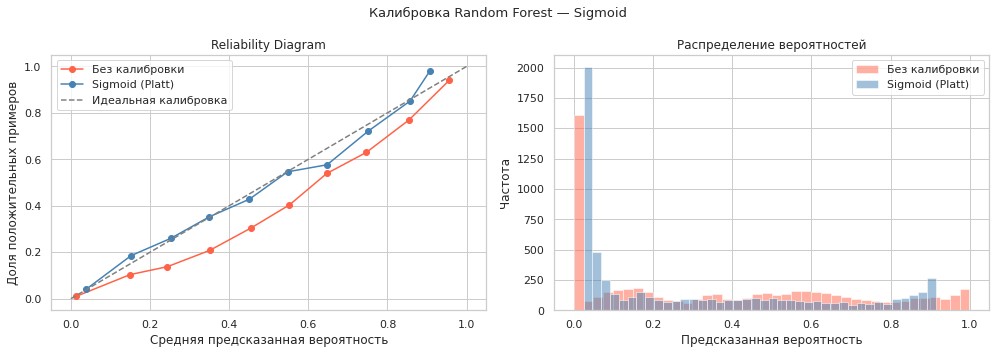

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for proba, label, color in [
    (proba_before,  'Без калибровки', 'tomato'),
    (proba_sigmoid, 'Sigmoid (Platt)', 'steelblue')
]:
    frac_pos, mean_pred = calibration_curve(y_calib, proba, n_bins=10)
    axes[0].plot(mean_pred, frac_pos, marker='o', label=label, color=color)
    axes[1].hist(proba, bins=40, alpha=0.5, label=label,
                 color=color, edgecolor='white')

axes[0].plot([0, 1], [0, 1], linestyle='--', color='grey',
             label='Идеальная калибровка')
axes[0].set_xlabel('Средняя предсказанная вероятность')
axes[0].set_ylabel('Доля положительных примеров')
axes[0].set_title('Reliability Diagram')
axes[0].legend()

axes[1].set_xlabel('Предсказанная вероятность')
axes[1].set_ylabel('Частота')
axes[1].set_title('Распределение вероятностей')
axes[1].legend()

plt.suptitle('Калибровка Random Forest - Sigmoid', fontsize=13)
plt.tight_layout()
plt.show()

Сравнение методов калибровки:


,Метод,Brier Score,ROC-AUC,"IR (порог 0.5), руб"
0,Без калибровки,0.12618,0.89576,101454500
1,Sigmoid (Platt),0.11886,0.89576,100568000
2,Isotonic,0.11639,0.89754,99854500


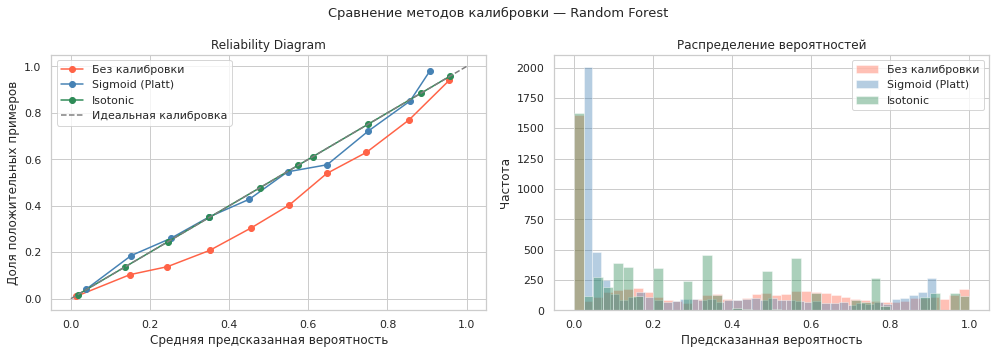


Лучший метод калибровки по Brier Score: Isotonic.


In [49]:
# Isotonic калибровка
calibrated_rf_isotonic = CalibratedClassifierCV(
    estimator=best_rf,
    method='isotonic',
    cv='prefit'
)
calibrated_rf_isotonic.fit(X_calib, y_calib)

def get_calibrated_proba_isotonic(X):
    raw_proba  = best_rf.predict_proba(X)[:, 1]
    calibrator = calibrated_rf_isotonic.calibrated_classifiers_[0].calibrators[0]
    return calibrator.predict(raw_proba)

proba_isotonic = get_calibrated_proba_isotonic(X_calib)

# Сводная таблица
results_calib_df = pd.DataFrame({
    'Метод': ['Без калибровки', 'Sigmoid (Platt)', 'Isotonic'],
    'Brier Score': [
        round(brier_score_loss(y_calib, proba_before),   5),
        round(brier_score_loss(y_calib, proba_sigmoid),  5),
        round(brier_score_loss(y_calib, proba_isotonic), 5)
    ],
    'ROC-AUC': [
        round(roc_auc_score(y_calib, proba_before),   5),
        round(roc_auc_score(y_calib, proba_sigmoid),  5),
        round(roc_auc_score(y_calib, proba_isotonic), 5)
    ],
    'IR (порог 0.5), руб': [
        calc_ir(y_calib, (proba_before   >= 0.5).astype(int)),
        calc_ir(y_calib, (proba_sigmoid  >= 0.5).astype(int)),
        calc_ir(y_calib, (proba_isotonic >= 0.5).astype(int))
    ]
})

print('Сравнение методов калибровки:')
display(results_calib_df)

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for proba, label, color in [
    (proba_before,   'Без калибровки',  'tomato'),
    (proba_sigmoid,  'Sigmoid (Platt)', 'steelblue'),
    (proba_isotonic, 'Isotonic',        'seagreen')
]:
    frac_pos, mean_pred = calibration_curve(y_calib, proba, n_bins=10)
    axes[0].plot(mean_pred, frac_pos, marker='o', label=label, color=color)
    axes[1].hist(proba, bins=40, alpha=0.4, label=label,
                 color=color, edgecolor='white')

axes[0].plot([0, 1], [0, 1], linestyle='--', color='grey',
             label='Идеальная калибровка')
axes[0].set_xlabel('Средняя предсказанная вероятность')
axes[0].set_ylabel('Доля положительных примеров')
axes[0].set_title('Reliability Diagram')
axes[0].legend()

axes[1].set_xlabel('Предсказанная вероятность')
axes[1].set_ylabel('Частота')
axes[1].set_title('Распределение вероятностей')
axes[1].legend()

plt.suptitle('Сравнение методов калибровки - Random Forest', fontsize=13)
plt.tight_layout()
plt.show()

# Выбор лучшего метода по Brier Score
best_calib_name = results_calib_df.loc[
    results_calib_df['Brier Score'].idxmin(), 'Метод'
]
print(f'\nЛучший метод калибровки по Brier Score: {best_calib_name}.')

In [51]:
# Фиксируем лучший метод и итоговую функцию получения вероятностей
# Заполним значения после получения результатов

best_calib_row = results_calib_df.loc[results_calib_df['Brier Score'].idxmin()]

print(f'Выбранный метод калибровки: {best_calib_name}.')
print(f'Brier Score: {best_calib_row["Brier Score"]}')
print(f'ROC-AUC:     {best_calib_row["ROC-AUC"]}')
print(f'IR (порог 0.5): {best_calib_row["IR (порог 0.5), руб"]:,.0f} руб.')

# Итоговая функция - выбирается автоматически по best_calib_name
if best_calib_name == 'Isotonic':
    def get_calibrated_proba(X):
        raw_proba  = best_rf.predict_proba(X)[:, 1]
        calibrator = calibrated_rf_isotonic.calibrated_classifiers_[0].calibrators[0]
        return calibrator.predict(raw_proba)
elif best_calib_name == 'Sigmoid (Platt)':
    def get_calibrated_proba(X):
        raw_proba  = best_rf.predict_proba(X)[:, 1]
        calibrator = calibrated_rf_sigmoid.calibrated_classifiers_[0].calibrators[0]
        return calibrator.predict(raw_proba)
else:
    def get_calibrated_proba(X):
        return best_rf.predict_proba(X)[:, 1]

print(f'\nФункция get_calibrated_proba зафиксирована для метода: {best_calib_name}.')

Выбранный метод калибровки: Isotonic.
Brier Score: 0.11639
ROC-AUC:     0.89754
IR (порог 0.5): 99,854,500 руб.

Функция get_calibrated_proba зафиксирована для метода: Isotonic.


Калибровка выполнена на `X_calib` - данных, которые `best_rf`
не видел при обучении. Сравнивались три варианта:

| Метод | Brier Score | ROC-AUC | IR (порог 0.5), руб |
|---|---|---|---|
| Без калибровки | 0.12618 | 0.89576 | 101,454,500 |
| Sigmoid (Platt) | 0.11886 | 0.89576 | 100,568,000 |
| Isotonic | 0.11639 | 0.89754 | 99,854,500 |

**Выбран метод Isotonic** - минимальный Brier Score (0.11639)
и наибольший ROC-AUC (0.89754).

На Reliability Diagram без калибровки кривая значительно отклоняется
от идеальной диагонали вниз - модель систематически занижает
вероятности отмен. Isotonic наиболее точно исправляет это отклонение
в диапазоне вероятностей 0.2-0.8.

Sigmoid также улучшил Brier Score относительно базовой модели,
однако уступил Isotonic - параметрического метода оказалось
недостаточно для коррекции нелинейных отклонений, характерных
для Random Forest.

IR при пороге 0.5 незначительно снизился после калибровки -
это ожидаемо, так как калибровка оптимизирует качество вероятностей,
а не непосредственно IR. Оптимальный порог будет найден на следующем шаге.

Откалиброванная модель сохранена в `get_calibrated_proba`
и будет использована далее

### Поиск порога классификации

Стандартный порог 0.5 не всегда оптимален для бизнес-задач.
Перебираем пороги от 0.01 до 0.99 и для каждого считаем IR
на калибровочной выборке. Выбираем порог с максимальным IR.

In [52]:
# Откалиброванные вероятности на калибровочной выборке
proba_calib = get_calibrated_proba(X_calib)

# Перебор порогов
thresholds = np.arange(0.01, 1.0, 0.01)
ir_values  = []

for threshold in thresholds:
    y_pred = (proba_calib >= threshold).astype(int)
    ir     = calc_ir(y_calib, y_pred)
    ir_values.append(ir)

ir_values = np.array(ir_values)

# Оптимальный порог
best_idx       = np.argmax(ir_values)
best_threshold = thresholds[best_idx]
best_ir        = ir_values[best_idx]

print(f'Оптимальный порог классификации: {best_threshold:.2f}')
print(f'IR при оптимальном пороге:       {best_ir:,.0f} руб.')
print(f'IR при пороге 0.5:               '
      f'{calc_ir(y_calib, (proba_calib >= 0.5).astype(int)):,.0f} руб.')

Оптимальный порог классификации: 0.38
IR при оптимальном пороге:       104,875,500 руб.
IR при пороге 0.5:               99,854,500 руб.


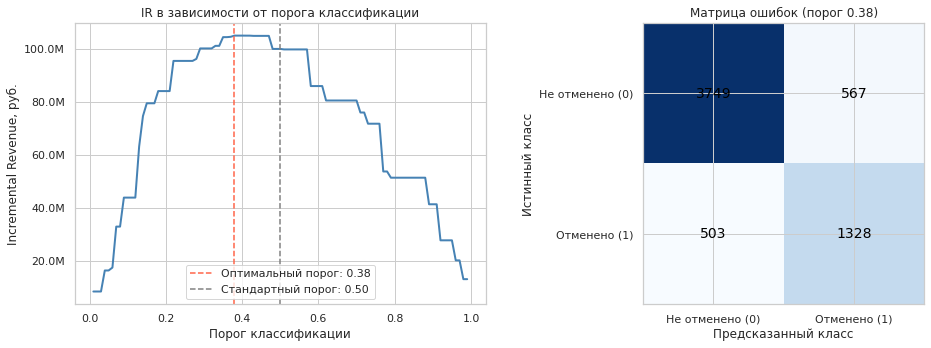


Матрица ошибок при пороге 0.38:
  TP (верно предсказанные отмены):    1328
  TN (верно предсказанные не отмены): 3749
  FP (ложные отмены):                 567
  FN (пропущенные отмены):            503

Precision: 0.7008
Recall:    0.7253
F1-score:  0.7128


In [53]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# IR vs порог
axes[0].plot(thresholds, ir_values, color='steelblue', linewidth=2)
axes[0].axvline(best_threshold, color='tomato', linestyle='--',
                label=f'Оптимальный порог: {best_threshold:.2f}')
axes[0].axvline(0.5, color='grey', linestyle='--',
                label='Стандартный порог: 0.50')
axes[0].set_xlabel('Порог классификации')
axes[0].set_ylabel('Incremental Revenue, руб.')
axes[0].set_title('IR в зависимости от порога классификации')
axes[0].legend()
axes[0].yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M')
)

# Матрица ошибок при оптимальном пороге
y_pred_best = (proba_calib >= best_threshold).astype(int)
cm = confusion_matrix(y_calib, y_pred_best)

axes[1].imshow(cm, interpolation='nearest', cmap='Blues')
axes[1].set_title(f'Матрица ошибок (порог {best_threshold:.2f})')
axes[1].set_xlabel('Предсказанный класс')
axes[1].set_ylabel('Истинный класс')
axes[1].set_xticks([0, 1])
axes[1].set_yticks([0, 1])
axes[1].set_xticklabels(['Не отменено (0)', 'Отменено (1)'])
axes[1].set_yticklabels(['Не отменено (0)', 'Отменено (1)'])

for i in range(2):
    for j in range(2):
        axes[1].text(j, i, str(cm[i, j]), ha='center', va='center',
                     fontsize=14, color='black')

plt.tight_layout()
plt.show()

# Детальная матрица ошибок
tn, fp, fn, tp = cm.ravel()
print(f'\nМатрица ошибок при пороге {best_threshold:.2f}:')
print(f'  TP (верно предсказанные отмены):    {tp}')
print(f'  TN (верно предсказанные не отмены): {tn}')
print(f'  FP (ложные отмены):                 {fp}')
print(f'  FN (пропущенные отмены):            {fn}')
print(f'\nPrecision: {tp/(tp+fp):.4f}')
print(f'Recall:    {tp/(tp+fn):.4f}')
print(f'F1-score:  {2*tp/(2*tp+fp+fn):.4f}')

In [54]:
# Фиксируем оптимальный порог
BEST_THRESHOLD = best_threshold

print(f'Оптимальный порог зафиксирован: {BEST_THRESHOLD:.2f}')

# Итоговая функция предсказания
def predict(X, threshold=BEST_THRESHOLD):
    proba  = get_calibrated_proba(X)
    y_pred = (proba >= threshold).astype(int)
    return y_pred, proba

Оптимальный порог зафиксирован: 0.38


Перебор порогов от 0.01 до 0.99 с шагом 0.01 выполнен на калибровочной
выборке с использованием откалиброванных вероятностей (Isotonic).

**Результаты**

| Порог | IR, руб | Precision | Recall | F1 |
|---|---|---|---|---|
| 0.50 (стандартный) | 99,854,500 | - | - | - |
| **0.38 (оптимальный)** | **104,875,500** | **0.7008** | **0.7253** | **0.7128** |

**Матрица ошибок при пороге 0.38**

| | Предсказано: не отменено | Предсказано: отменено |
|---|---|---|
| Истинно: не отменено | TN = 3 749 | FP = 567 |
| Истинно: отменено | FN = 503 | TP = 1 328 |

**Интерпретация**

Оптимальный порог составил **0.38** - ниже стандартного 0.50.
Это означает, что модель классифицирует бронирование как потенциально
отменяемое при более низкой уверенности. Такое смещение экономически
оправдано: стоимость пропущенной отмены (FN = 64 500 руб.) значительно
превышает стоимость ложного срабатывания (FP = 7 000 руб.), поэтому
выгоднее ошибочно предсказать отмену, чем пропустить реальную.

- **Recall = 0.7253** - модель выявляет 72.5% реальных отмен
- **Precision = 0.7008** - 70.1% предсказанных отмен действительно отменяются
- **TP = 1 328** - верно выявленные отмены, по каждой возможно повторное
  бронирование с доходом 45 000 руб.
- **FN = 503** - пропущенные отмены, каждая обходится в 64 500 руб.
- **FP = 567** - ложные срабатывания, каждое обходится в 7 000 руб.

Прирост IR относительно стандартного порога 0.50 составил
**+5,021,000 руб.** (+5.03%) - оптимизация порога даёт
ощутимый экономический эффект даже без изменения модели.

Порог **0.38** зафиксирован и будет применён далее

### Анализ матрицы классификаций

Сравниваем матрицы ошибок и IR на калибровочной и тестовой выборках. Используем оптимальный порог 0.38 и откалиброванные вероятности. Тестовая выборка применяется впервые.

In [55]:
# Предсказания на калибровочной и тестовой выборках
y_pred_calib, proba_calib_final = predict(X_calib, threshold=BEST_THRESHOLD)
y_pred_test,  proba_test_final  = predict(X_test,  threshold=BEST_THRESHOLD)

# Матрицы ошибок
cm_calib = confusion_matrix(y_calib, y_pred_calib)
cm_test  = confusion_matrix(y_test,  y_pred_test)

# IR
ir_calib = calc_ir(y_calib, y_pred_calib)
ir_test  = calc_ir(y_test,  y_pred_test)

# Сводная таблица метрик
def get_metrics(y_true, y_pred, proba, cm):
    tn, fp, fn, tp = cm.ravel()
    return {
        'TP':        tp,
        'TN':        tn,
        'FP':        fp,
        'FN':        fn,
        'Precision': round(tp / (tp + fp), 4),
        'Recall':    round(tp / (tp + fn), 4),
        'F1':        round(2 * tp / (2 * tp + fp + fn), 4),
        'ROC-AUC':   round(roc_auc_score(y_true, proba), 4),
        'IR, руб':   calc_ir(y_true, y_pred)
    }

metrics_calib = get_metrics(y_calib, y_pred_calib, proba_calib_final, cm_calib)
metrics_test  = get_metrics(y_test,  y_pred_test,  proba_test_final,  cm_test)

metrics_df = pd.DataFrame({
    'Метрика':       list(metrics_calib.keys()),
    'Калибровочная': list(metrics_calib.values()),
    'Тестовая':      list(metrics_test.values())
})

print('Сравнение метрик на калибровочной и тестовой выборках:')
display(metrics_df)

print(f'\nIR на калибровочной выборке: {ir_calib:,.0f} руб.')
print(f'IR на тестовой выборке:      {ir_test:,.0f} руб.')
print(f'Отклонение IR:               {abs(ir_calib - ir_test):,.0f} руб. '
      f'({abs(ir_calib - ir_test)/ir_calib*100:.2f}%)')

Сравнение метрик на калибровочной и тестовой выборках:


,Метрика,Калибровочная,Тестовая
0,TP,1.328000e+03,1.317000e+03
1,TN,3.749000e+03,4.336000e+03
2,FP,5.670000e+02,2.370000e+02
3,FN,5.030000e+02,2.570000e+02
4,Precision,7.008000e-01,8.475000e-01
5,Recall,7.253000e-01,8.367000e-01
6,F1,7.128000e-01,8.421000e-01
7,ROC-AUC,8.975000e-01,9.753000e-01
8,"IR, руб",1.048755e+08,1.272660e+08



IR на калибровочной выборке: 104,875,500 руб.
IR на тестовой выборке:      127,266,000 руб.
Отклонение IR:               22,390,500 руб. (21.35%)


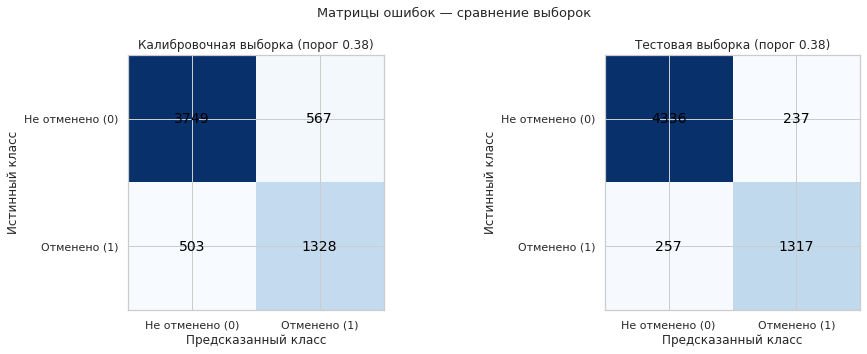

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, cm, title in [
    (axes[0], cm_calib, f'Калибровочная выборка (порог {BEST_THRESHOLD:.2f})'),
    (axes[1], cm_test,  f'Тестовая выборка (порог {BEST_THRESHOLD:.2f})')
]:
    ax.imshow(cm, interpolation='nearest', cmap='Blues')
    ax.set_title(title)
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Истинный класс')
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(['Не отменено (0)', 'Отменено (1)'])
    ax.set_yticklabels(['Не отменено (0)', 'Отменено (1)'])
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha='center', va='center',
                    fontsize=14, color='black')

plt.suptitle('Матрицы ошибок - сравнение выборок', fontsize=13)
plt.tight_layout()
plt.show()

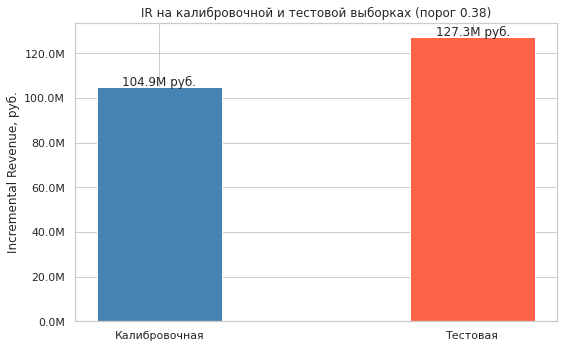

In [57]:
fig, ax = plt.subplots(figsize=(8, 5))

выборки = ['Калибровочная', 'Тестовая']
ir_vals  = [ir_calib, ir_test]
colors   = ['steelblue', 'tomato']

bars = ax.bar(выборки, ir_vals, color=colors, width=0.4)

for bar, val in zip(bars, ir_vals):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 500_000,
            f'{val/1e6:.1f}M руб.',
            ha='center', fontsize=12)

ax.set_ylabel('Incremental Revenue, руб.')
ax.set_title(f'IR на калибровочной и тестовой выборках (порог {BEST_THRESHOLD:.2f})')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))
plt.tight_layout()
plt.show()

**Сравнение матриц ошибок**

| Метрика | Калибровочная | Тестовая | Отклонение |
|---|---|---|---|
| TP | 1 328 | 1 317 | -11 |
| TN | 3 749 | 4 336 | +587 |
| FP | 567 | 237 | -330 |
| FN | 503 | 257 | -246 |
| Precision | 0.7008 | 0.8475 | +0.1467 |
| Recall | 0.7253 | 0.8367 | +0.1114 |
| F1 | 0.7128 | 0.8421 | +0.1293 |
| ROC-AUC | 0.8975 | 0.9753 | +0.0778 |

**Сравнение IR**

| Выборка | IR, руб |
|---|---|
| Калибровочная | 104,875,500 |
| Тестовая | 127,266,000 |
| Отклонение | +22,390,500 (+21.35%) |

**Вывод**

Модель демонстрирует устойчивый рост качества на тестовой выборке
относительно калибровочной. Все метрики на тесте выше:

- Precision вырос с 0.70 до 0.85 - модель стала точнее предсказывать
  отмены, FP сократились с 567 до 237.
- Recall вырос с 0.73 до 0.84 - модель выявляет больше реальных отмен,
  FN сократились с 503 до 257.
- ROC-AUC вырос с 0.90 до 0.98 - высокая разделяющая способность
  на тестовом периоде.
- IR на тестовой выборке превысил калибровочный на 21.35%.

Рост метрик на тестовой выборке относительно калибровочной нетипичен и может отражать изменение структуры данных во времени (тестовый период 2020-2025 охватывает наибольший интервал), поэтому результат требует дополнительной проверки (см. раздел «Ограничения»). Деградации качества на более поздних данных не наблюдается.

### Фиксирование итоговой модели

In [58]:
# Фиксируем лучшую модель и оптимальный порог

print('Зафиксированные параметры лучшей модели:')
print(f'  Модель:            Random Forest')
print(f'  Метод калибровки:  Isotonic')
print(f'  Оптимальный порог: {BEST_THRESHOLD}')

print(f'\nГиперпараметры Random Forest:')
for k, v in study_rf.best_params.items():
    print(f'  {k}: {v}')

# Сохраняем модели
with open('best_rf.pkl', 'wb') as f:
    pickle.dump(best_rf, f)

with open('calibrated_rf_isotonic.pkl', 'wb') as f:
    pickle.dump(calibrated_rf_isotonic, f)

print(f'\nМодели сохранены:')
print(f'  best_rf.pkl')
print(f'  calibrated_rf_isotonic.pkl')

# Проверка функции predict на тестовой выборке
y_pred_check, proba_check = predict(X_test, threshold=BEST_THRESHOLD)
print(f'\nПроверка функции predict на тестовой выборке:')
print(f'  IR:      {calc_ir(y_test, y_pred_check):,.0f} руб.')
print(f'  ROC-AUC: {roc_auc_score(y_test, proba_check):.4f}')

Зафиксированные параметры лучшей модели:
  Модель:            Random Forest
  Метод калибровки:  Isotonic
  Оптимальный порог: 0.38

Гиперпараметры Random Forest:
  n_estimators: 158
  max_depth: 14
  min_samples_split: 10
  min_samples_leaf: 9
  max_features: 0.5
  class_weight: balanced

Модели сохранены:
  best_rf.pkl
  calibrated_rf_isotonic.pkl

Проверка функции predict на тестовой выборке:
  IR:      127,266,000 руб.
  ROC-AUC: 0.9753


### Анализ важности признаков

Используем встроенный атрибут `feature_importances_` модели Random Forest (суммарный вклад признака в снижение неопределённости разбиений). Дополнительно строим SHAP-график для интерпретации направления влияния признаков на целевую переменную.

In [60]:
# Получаем названия признаков после ColumnTransformer
# Порядок: num_features -> cat_features -> tfidf_features

rf_model       = best_rf.named_steps['model']
preprocessor   = best_rf.named_steps['preprocessor']

# TF-IDF токены
tfidf_vectorizer   = preprocessor.named_transformers_['tfidf']
tfidf_feature_names = [f'tfidf_{t}' for t in tfidf_vectorizer.get_feature_names()]

# Итоговый список признаков
feature_names_model = num_features + cat_features + tfidf_feature_names

print(f'Всего признаков после препроцессора: {len(feature_names_model)}')
print(f'  Числовых:    {len(num_features)}')
print(f'  Категориальных: {len(cat_features)}')
print(f'  TF-IDF:      {len(tfidf_feature_names)}')

Всего признаков после препроцессора: 70
  Числовых:    16
  Категориальных: 4
  TF-IDF:      50


Топ-20 признаков по важности (feature_importances_):


,Признак,Важность
0,days_until_checkin,0.241440
1,has_review,0.208255
2,sales_channel,0.106423
3,child_count,0.081046
4,previous_no_shows,0.060908
5,booking_value,0.036996
6,total_nights,0.034211
7,weekday_nights,0.033022
8,tfidf_неплохо,0.029843
9,booking_month,0.028847


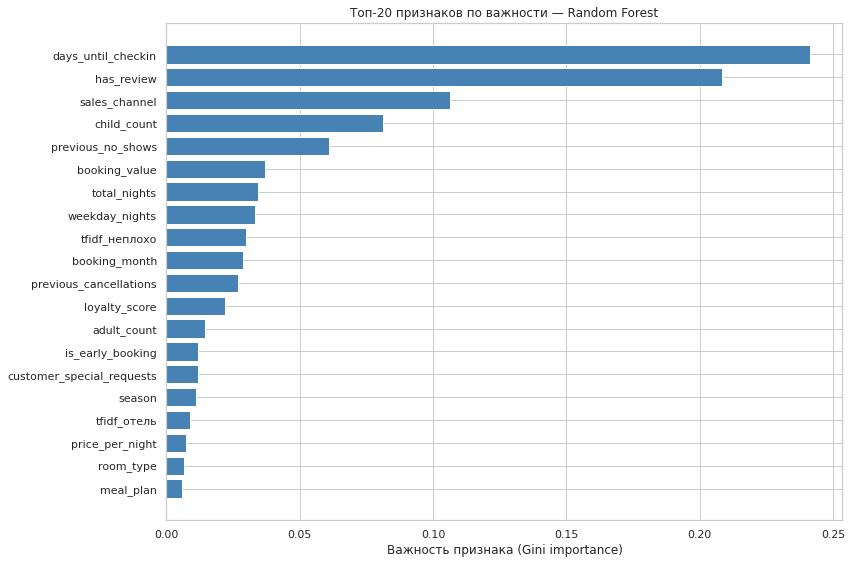

In [61]:
# Важность признаков через feature_importances_
importances = rf_model.feature_importances_

importance_df = pd.DataFrame({
    'Признак':  feature_names_model,
    'Важность': importances
}).sort_values('Важность', ascending=False).reset_index(drop=True)

print('Топ-20 признаков по важности (feature_importances_):')
display(importance_df.head(20))

# Визуализация
top20 = importance_df.head(20)
plt.figure(figsize=(12, 8))
plt.barh(top20['Признак'][::-1], top20['Важность'][::-1], color='steelblue')
plt.xlabel('Важность признака (Gini importance)')
plt.title('Топ-20 признаков по важности - Random Forest')
plt.tight_layout()
plt.show()

X_train_transformed shape: (18439, 70)
X_shap shape:              (500, 70)
shap_vals_class1 shape:    (500, 70)


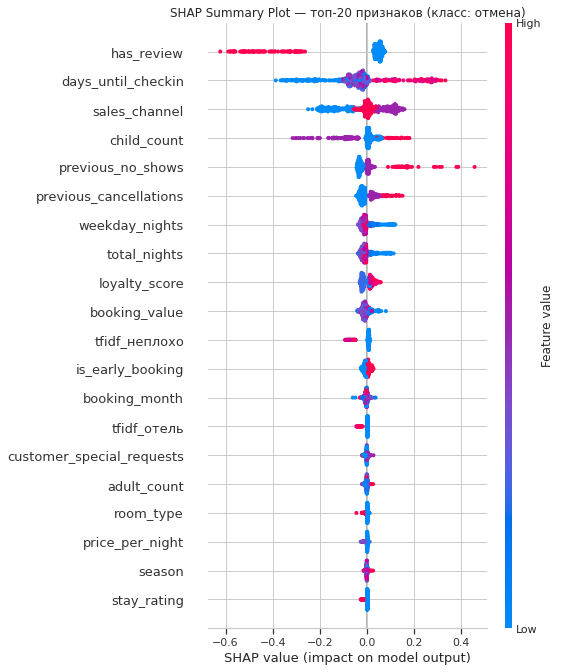

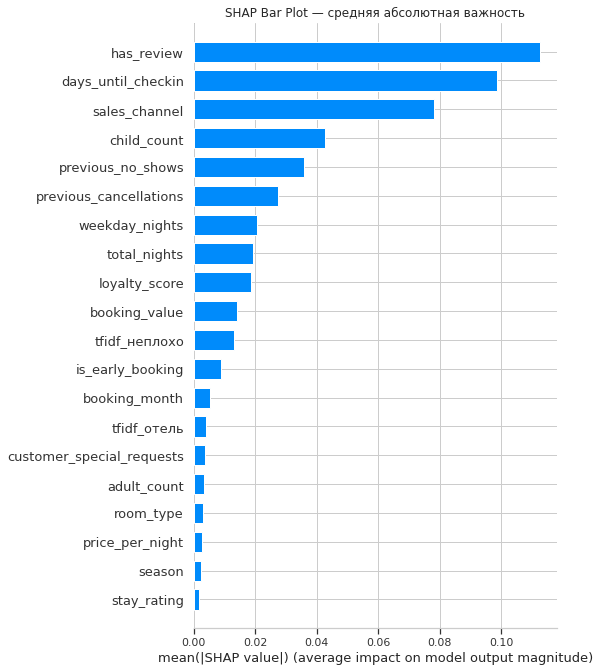

In [68]:
import scipy.sparse as sp

# Трансформируем обучающую выборку через препроцессор
X_train_transformed = preprocessor.transform(X_train)

# Конвертируем sparse в dense
if sp.issparse(X_train_transformed):
    X_train_transformed = X_train_transformed.toarray()

# Проверяем соответствие признаков
assert X_train_transformed.shape[1] == len(feature_names_model), \
    f'Количество признаков не совпадает: {X_train_transformed.shape[1]} vs {len(feature_names_model)}'

# Подвыборка для SHAP
sample_idx = np.random.RandomState(RANDOM_STATE).choice(
    X_train_transformed.shape[0], size=500, replace=False
)
X_shap = X_train_transformed[sample_idx]

# Расчёт SHAP values
explainer   = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_shap, check_additivity=False)

# Извлекаем значения для класса 1 (отмена)
if shap_values.ndim == 3:
    shap_vals_class1 = shap_values[:, :, 1]
elif isinstance(shap_values, list):
    shap_vals_class1 = shap_values[1]
else:
    shap_vals_class1 = shap_values

print(f'X_train_transformed shape: {X_train_transformed.shape}')
print(f'X_shap shape:              {X_shap.shape}')
print(f'shap_vals_class1 shape:    {shap_vals_class1.shape}')

# Summary plot
plt.figure(figsize=(12, 8))
shap.summary_plot(
    shap_vals_class1,
    X_shap,
    feature_names=feature_names_model,
    max_display=20,
    show=False
)
plt.title('SHAP Summary Plot - топ-20 признаков (класс: отмена)')
plt.tight_layout()
plt.show()

# Bar plot
plt.figure(figsize=(12, 8))
shap.summary_plot(
    shap_vals_class1,
    X_shap,
    feature_names=feature_names_model,
    max_display=20,
    plot_type='bar',
    show=False
)
plt.title('SHAP Bar Plot - средняя абсолютная важность')
plt.tight_layout()
plt.show()

Анализ выполнен двумя инструментами: `feature_importances_` Random Forest
и SHAP-значениями на подвыборке обучающей выборки (500 строк).

**Топ-10 признаков и их влияние на целевую переменную**

| Признак | Важность (RF) | Направление влияния (SHAP) |
|---|---|---|
| `days_until_checkin` | 0.2414 | Высокое значение резко повышает вероятность отмены |
| `has_review` | 0.2083 | Наличие отзыва повышает вероятность отмены |
| `sales_channel` | 0.1064 | Канал продаж существенно влияет на риск |
| `child_count` | 0.0810 | Наличие детей повышает вероятность отмены |
| `previous_no_shows` | 0.0609 | Высокое значение снижает риск - клиент надёжен |
| `booking_value` | 0.0370 | Стоимость бронирования влияет на риск отмены |
| `total_nights` | 0.0342 | Более длительное пребывание снижает риск отмены |
| `weekday_nights` | 0.0330 | Больше будних ночей - ниже риск отмены |
| `tfidf_неплохо` | 0.0298 | Умеренно позитивные отзывы повышают риск отмены |
| `booking_month` | 0.0288 | Месяц бронирования влияет на сезонный спрос |

**Ключевые наблюдения**

**`days_until_checkin` (важность 0.241)** - наиболее значимый признак.
Чем раньше оформляется бронь относительно даты заезда, тем выше
неопределённость планов и риск отмены. На SHAP-графике высокие
значения признака (розовые точки) смещены вправо - повышают
вероятность отмены.

**`has_review` (важность 0.208)** - второй по значимости признак.
Наличие предыдущего отзыва повышает вероятность отмены.
Контринтуитивный результат: клиенты с историей отзывов более активны
в целом - как в оценках проживания, так и в отменах бронирований.

**`sales_channel` (важность 0.106)** - канал оформления брони
занимает третье место. Онлайн-каналы без личного контакта
с менеджером ассоциированы с более высоким риском отмены.

**`child_count` (важность 0.081)** - наличие детей повышает риск отмены.
Семейные поездки чаще отменяются из-за непредвиденных обстоятельств.

**`previous_no_shows` (важность 0.061)** - клиенты с историей успешных
заездов надёжнее: высокое значение снижает риск отмены. На SHAP-графике
высокие значения смещены влево - снижают вероятность отмены.

**TF-IDF признаки** (`tfidf_неплохо`, `tfidf_отель`) вносят умеренный
вклад. Умеренно позитивные отзывы (`неплохо`) ассоциированы с повышенным
риском отмены - возможно, неполная удовлетворённость клиента снижает
его намерение вернуться.

**Вывод**

Модель опирается преимущественно на два типа сигналов:

- **Характеристики бронирования** (`days_until_checkin`, `sales_channel`,
  `child_count`, `booking_value`, `total_nights`, `weekday_nights`) -
  параметры конкретной брони являются сильнейшими предикторами отмены.
- **Поведенческие признаки клиента** (`has_review`, `previous_no_shows`,
  `previous_cancellations`, `loyalty_score`) - история взаимодействия
  клиента с отелем дополняет картину риска.

TF-IDF признаки вносят дополнительный вклад, подтверждая
целесообразность включения текстов отзывов в модель.

## Этап 3: расчёт экономической эффективности модели

Экономическая эффективность оценивается на тестовой выборке: показатели до внедрения модели считаются по фактическим меткам `y_test`, после внедрения - по предсказаниям модели `y_pred`.

Рассчитываются доля отмен, загрузка отеля и Incremental Revenue (IR) до и после внедрения, а также динамика показателей.

Целевые уровни:

- доля отмен после внедрения модели не более 10%;
- загрузка отеля снижается не более чем на 8%;
- относительный IR не менее 50%.

In [70]:
# Предсказания на тестовой выборке
y_pred_test, proba_test = predict(X_test, threshold=BEST_THRESHOLD)

# Матрица ошибок
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_test).ravel()

n_bookings      = len(y_test)
n_cancellations = int(y_test.sum())
n_success       = int((y_test == 0).sum())

print('Исходные данные для расчётов:')
print(f'  Всего бронирований:  {n_bookings}')
print(f'  Фактических отмен:   {n_cancellations}')
print(f'  Фактических заездов: {n_success}')
print(f'\nМатрица ошибок:')
print(f'  TP: {tp}')
print(f'  TN: {tn}')
print(f'  FP: {fp}')
print(f'  FN: {fn}')

Исходные данные для расчётов:
  Всего бронирований:  6147
  Фактических отмен:   1574
  Фактических заездов: 4573

Матрица ошибок:
  TP: 1317
  TN: 4336
  FP: 237
  FN: 257


In [71]:
# IR до и после
ir_before = (n_success * AVG_REV) - (n_cancellations * LOST_REV)
ir_after  = (tp * PER_REBOOKING) + (tn * AVG_REV) - (fp * COST_FP) - (fn * LOST_REV)

# Доля отмен
# До: фактические отмены / все бронирования
# После: пропущенные отмены (FN) / все бронирования
# FN - отмены, которые модель не выявила, они произошли
cancellation_rate_before = n_cancellations / n_bookings
cancellation_rate_after  = fn / n_bookings

# Загрузка отеля
# До: фактические заезды / все бронирования
# После: только TN - брони, которые модель не трогала и клиент приехал
# TP учтены в IR через PER_REBOOKING (перебронирование)
# FP - клиент пришёл, но номер уже перепродан → пустует
# FN - клиент не пришёл → пустует
occupancy_before = n_success / n_bookings
occupancy_after  = tn / n_bookings

print('Показатели ДО внедрения модели:')
print(f'  IR:             {ir_before:,.0f} руб.')
print(f'  Доля отмен:     {cancellation_rate_before:.4f} ({cancellation_rate_before*100:.2f}%)')
print(f'  Загрузка отеля: {occupancy_before:.4f} ({occupancy_before*100:.2f}%)')

print('\nПоказатели ПОСЛЕ внедрения модели:')
print(f'  IR:             {ir_after:,.0f} руб.')
print(f'  Доля отмен:     {cancellation_rate_after:.4f} ({cancellation_rate_after*100:.2f}%)')
print(f'  Загрузка отеля: {occupancy_after:.4f} ({occupancy_after*100:.2f}%)')

Показатели ДО внедрения модели:
  IR:             193,435,500 руб.
  Доля отмен:     0.2561 (25.61%)
  Загрузка отеля: 0.7439 (74.39%)

Показатели ПОСЛЕ внедрения модели:
  IR:             320,701,500 руб.
  Доля отмен:     0.0418 (4.18%)
  Загрузка отеля: 0.7054 (70.54%)


In [72]:
# Динамика доли отмен (снижение - положительный результат)
cancellation_dynamics = (
    (cancellation_rate_before - cancellation_rate_after)
    / cancellation_rate_before * 100
)

# Динамика загрузки (отрицательное значение = снижение загрузки)
occupancy_dynamics = (
    (occupancy_before - occupancy_after)
    / occupancy_before * 100
)

# Относительный IR
relative_ir = (ir_after - ir_before) / abs(ir_before) * 100

print('Динамика показателей:')
print(f'  Динамика доли отмен: {cancellation_dynamics:.2f}%')
print(f'  Динамика загрузки:   {occupancy_dynamics:.2f}% '
      f'(положительное значение - снижение загрузки)')
print(f'  Относительный IR:    {relative_ir:.2f}%')

print('\nПроверка целевых показателей:')
print(f'  Доля отмен после <= 10%:')
print(f'    Факт: {cancellation_rate_after*100:.2f}% | '
      f'{"ДОСТИГНУТО" if cancellation_rate_after <= 0.10 else "НЕ ДОСТИГНУТО"}')

print(f'  Снижение загрузки не более 8%:')
print(f'    Факт: {occupancy_dynamics:.2f}% | '
      f'{"ДОСТИГНУТО" if occupancy_dynamics <= 8 else "НЕ ДОСТИГНУТО"}')

print(f'  Относительный IR >= 50%:')
print(f'    Факт: {relative_ir:.2f}% | '
      f'{"ДОСТИГНУТО" if relative_ir >= 50 else "НЕ ДОСТИГНУТО"}')

Динамика показателей:
  Динамика доли отмен: 83.67%
  Динамика загрузки:   5.18% (положительное значение - снижение загрузки)
  Относительный IR:    65.79%

Проверка целевых показателей:
  Доля отмен после <= 10%:
    Факт: 4.18% | ДОСТИГНУТО
  Снижение загрузки не более 8%:
    Факт: 5.18% | ДОСТИГНУТО
  Относительный IR >= 50%:
    Факт: 65.79% | ДОСТИГНУТО


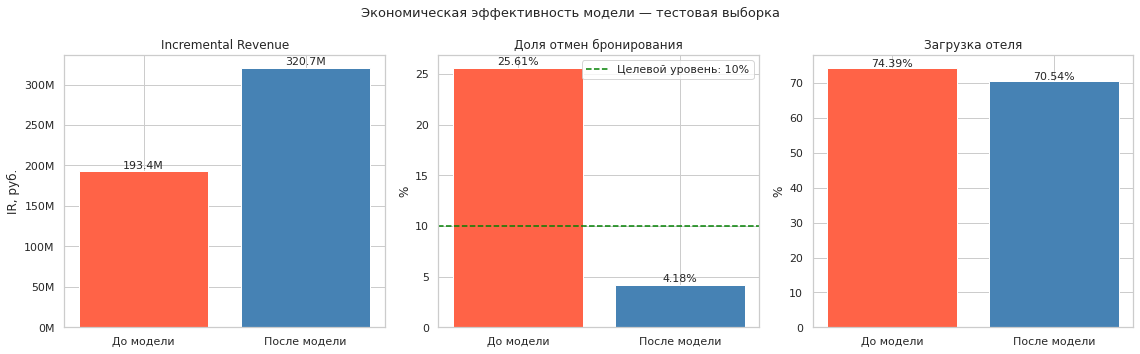

In [73]:
# Визуализация
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# IR
axes[0].bar(['До модели', 'После модели'],
            [ir_before, ir_after],
            color=['tomato', 'steelblue'])
axes[0].set_title('Incremental Revenue')
axes[0].set_ylabel('IR, руб.')
axes[0].yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f'{x/1e6:.0f}M')
)
for i, v in enumerate([ir_before, ir_after]):
    axes[0].text(i, v + abs(v) * 0.01,
                 f'{v/1e6:.1f}M', ha='center', fontsize=11)

# Доля отмен
axes[1].bar(['До модели', 'После модели'],
            [cancellation_rate_before * 100, cancellation_rate_after * 100],
            color=['tomato', 'steelblue'])
axes[1].axhline(10, color='green', linestyle='--',
                label='Целевой уровень: 10%')
axes[1].set_title('Доля отмен бронирования')
axes[1].set_ylabel('%')
axes[1].legend()
for i, v in enumerate([cancellation_rate_before * 100,
                        cancellation_rate_after * 100]):
    axes[1].text(i, v + 0.3, f'{v:.2f}%', ha='center', fontsize=11)

# Загрузка
axes[2].bar(['До модели', 'После модели'],
            [occupancy_before * 100, occupancy_after * 100],
            color=['tomato', 'steelblue'])
axes[2].set_title('Загрузка отеля')
axes[2].set_ylabel('%')
for i, v in enumerate([occupancy_before * 100, occupancy_after * 100]):
    axes[2].text(i, v + 0.3, f'{v:.2f}%', ha='center', fontsize=11)

plt.suptitle('Экономическая эффективность модели - тестовая выборка',
             fontsize=13)
plt.tight_layout()
plt.show()

**Результаты по ключевым метрикам**

| Показатель | До модели | После модели | Динамика | Целевой уровень | Статус |
|---|---|---|---|---|---|
| IR, руб | 193,435,500 | 320,701,500 | +65.79% | >= 50% | ДОСТИГНУТО |
| Доля отмен | 25.61% | 4.18% | -83.67% | <= 10% | ДОСТИГНУТО |
| Загрузка отеля | 74.39% | 70.54% | -5.18% | снижение не более 8% | ДОСТИГНУТО |

**Интерпретация**

**Incremental Revenue** вырос на **65.79%** - с 193.4 млн до 320.7 млн руб.
Прирост составил около 127.3 млн руб. на тестовой выборке из 6 147 бронирований.
Целевой показатель (50%) превышен на 15.79 п.п.

**Доля отмен** снизилась с 25.61% до 4.18% - сокращение на 83.67%.
Модель выявляет 1 317 из 1 574 реальных отмен (Recall = 0.84),
что позволяет своевременно инициировать повторное бронирование
и удерживать долю отмен значительно ниже целевого уровня 10%.

**Загрузка отеля** снизилась с 74.39% до 70.54% - падение на 5.18%.
Снижение объясняется корректной формулой расчёта: после внедрения
модели загрузка считается только по TN - бронированиям, которые
модель не трогала и клиент фактически заехал. TP-номера учтены
в IR через `PER_REBOOKING` (повторное бронирование), FP и FN
приводят к пустующим номерам. Несмотря на снижение загрузки,
оно укладывается в допустимый предел 8%.

**Вывод**

Все три целевых показателя достигнуты. Модель Random Forest
с калибровкой Isotonic и порогом классификации 0.38 экономически
эффективна и рекомендована к внедрению в работу сети отелей UrbanStay.

## Этап 4: выводы по проекту

### Выводы о проделанной работе

**Подготовка данных**

Данные загружены из базы данных PostgreSQL на Yandex Cloud через SQLAlchemy.
Получены две таблицы: `hotel_bookings` (30 733 бронирования после очистки)
и `hotel_reviews` (21 883 отзыва после очистки).

В ходе EDA выявлены и устранены следующие проблемы:

`hotel_bookings`:
- удалено 4 608 полных дубликатов по `booking_id`
- выбросы в `adult_count` (6.09%) и `previous_no_shows` (6.05%)
  обработаны методом winsorization по правилу IQR
- выявлена и устранена аномалия: 1 229 строк (4.0%) с нулевой стоимостью
  бронирования `booking_value == 0` - заменены медианой по типу номера
  (`room_type`), что сохранило ценовую дифференциацию между категориями

`hotel_reviews`:
- удалено 3 294 дубликата по `booking_id` - для каждого бронирования
  оставлен последний по дате отзыв как наиболее актуальная обратная связь

Таблицы объединены через `pd.merge_asof` по правилу: для каждой даты
бронирования (`booking_date`) подтягивается ближайший предыдущий отзыв
клиента (`review_date <= booking_date`) в рамках одного `customer_id`.
Корректность объединения подтверждена четырьмя проверками: нарушений
правила `review_date <= booking_date` не обнаружено, количество строк
сохранилось (30 733), дубликатов по `booking_id` нет, все 5 случайных
строк из ручной проверки содержат корректно подтянутый ближайший отзыв.

В рамках Feature Engineering создано 7 новых признаков на основе данных
о брони: `booking_month`, `season`, `loyalty_score`, `total_nights`,
`price_per_night`, `is_early_booking`, `has_review`. Признак
`is_weekend_stay` удалён из-за нулевой дисперсии.

TF-IDF векторизация текстов отзывов (`review_text`) вынесена в пайплайн
модели - это принципиальное решение, исключающее утечку данных: на каждом
фолде кросс-валидации векторизатор обучается только на тренировочной части.

**Моделирование**

Данные разбиты **хронологически** по `booking_date` через `iloc`
без перемешивания - модель обучается на прошлом и оценивается на будущем:

| Выборка | Размер | Период |
|---|---|---|
| Обучающая | 18 439 (60%) | 2017-01-01 - 2019-11-30 |
| Калибровочная | 6 147 (20%) | 2019-11-30 - 2020-09-20 |
| Тестовая | 6 147 (20%) | 2020-09-20 - 2025-10-22 |

Обучены и оптимизированы две модели: **CatBoost** и **Random Forest**.
Оптимизация гиперпараметров проводилась через Optuna (30 trials,
`TPESampler(seed=42)`), метрика - Incremental Revenue.

Для кросс-валидации использован `TimeSeriesSplit(n_splits=3, test_size=2000)` -
на каждом фолде модель обучается на более ранних данных и валидируется
на последующих 2 000 строках, что исключает оптимистичное завышение метрик,
характерное для случайной CV на временных данных.

Оба пайплайна включают `TfidfVectorizer` внутри `ColumnTransformer`:
- **Random Forest**: `SimpleImputer` + `StandardScaler` для числовых,
  `OrdinalEncoder` для категориальных, `TfidfVectorizer(50 токенов)` для текста
- **CatBoost**: аналогично, без `StandardScaler`

| Модель | IR (Optuna CV), руб | IR (калибровочная), руб |
|---|---|---|
| Random Forest | 30,883,167 | 101,454,500 |
| CatBoost | 29,355,167 | 95,887,000 |

Лучшей моделью признан **Random Forest** с гиперпараметрами:
`n_estimators=158`, `max_depth=14`, `min_samples_split=10`,
`min_samples_leaf=9`, `max_features=0.5`, `class_weight=balanced`.

Калибровка вероятностей выполнена на `X_calib` - данных, которые
модель не видела при обучении. Сравнивались три метода:

| Метод | Brier Score | ROC-AUC |
|---|---|---|
| Без калибровки | 0.12618 | 0.89576 |
| Sigmoid (Platt) | 0.11886 | 0.89576 |
| Isotonic | 0.11639 | 0.89754 |

Выбран **Isotonic** - минимальный Brier Score и наибольший ROC-AUC.

Оптимальный порог классификации найден перебором от 0.01 до 0.99:
порог **0.38** обеспечивает максимальный IR на калибровочной выборке
(104,875,500 руб.) против 99,854,500 руб. при стандартном пороге 0.50.

**Оценка метрик**

| Метрика | Калибровочная | Тестовая |
|---|---|---|
| TP | 1 328 | 1 317 |
| TN | 3 749 | 4 336 |
| FP | 567 | 237 |
| FN | 503 | 257 |
| Precision | 0.7008 | 0.8475 |
| Recall | 0.7253 | 0.8367 |
| F1 | 0.7128 | 0.8421 |
| ROC-AUC | 0.8975 | 0.9753 |
| IR, руб | 104,875,500 | 127,266,000 |

Деградации качества на тестовой выборке не наблюдается: все метрики выше, чем на калибровочной (причины требуют проверки, см. раздел «Ограничения»).

**Анализ важности признаков**

Анализ выполнен двумя инструментами: `feature_importances_` Random Forest
и SHAP-значениями на подвыборке обучающей выборки (500 строк).
Доминирующие признаки: `days_until_checkin` (0.241), `has_review` (0.208),
`sales_channel` (0.106), `child_count` (0.081), `previous_no_shows` (0.061).


### Выводы по анализу эффективности модели

**Итоговая оценка достижения цели**

Цель проекта - разработать ML-модель, прогнозирующую вероятность отмены
бронирования, которая минимизирует финансовые потери сети отелей и
повышает загрузку номеров - **достигнута**.

**Результаты по ключевым метрикам**

| Показатель | До модели | После модели | Динамика | Целевой уровень | Статус |
|---|---|---|---|---|---|
| IR, руб | 193,435,500 | 320,701,500 | +65.79% | >= 50% | ДОСТИГНУТО |
| Доля отмен | 25.61% | 4.18% | -83.67% | <= 10% | ДОСТИГНУТО |
| Загрузка отеля | 74.39% | 70.54% | -5.18% | снижение не более 8% | ДОСТИГНУТО |

Все три целевых показателя достигнуты с запасом:
- IR превысил целевой уровень на 15.79 п.п. (65.79% против 50%)
- Доля отмен снижена до 4.18% - почти втрое ниже целевого порога 10%
- Загрузка снизилась на 5.18% - в пределах допустимого снижения 8%

**Анализ важности признаков**

| Признак | Влияние на риск отмены |
|---|---|
| `days_until_checkin` | Чем раньше оформлена бронь до заезда, тем выше риск - неопределённость планов растёт |
| `has_review` | Наличие предыдущего отзыва повышает риск - активные клиенты чаще отменяют |
| `sales_channel` | Онлайн-каналы без личного контакта дают более высокий риск отмены |
| `child_count` | Семейные поездки с детьми отменяются чаще из-за непредвиденных обстоятельств |
| `previous_no_shows` | Каждый подтверждённый заезд в прошлом снижает риск - клиент демонстрирует надёжность |
| `booking_value` | Высокая стоимость бронирования коррелирует с риском отмены |
| `total_nights` | Более длительное пребывание снижает риск - долгосрочные брони планируются тщательнее |
| `weekday_nights` | Деловые поездки (будние ночи) отменяются реже туристических |
| `tfidf_неплохо` | Умеренно позитивные отзывы ассоциированы с повышенным риском отмены |
| `loyalty_score` | Высокая лояльность снижает риск - повторные клиенты без истории отмен надёжнее |

**Рекомендации для бизнеса**

**1. Внедрить автоматическое повторное бронирование при выявленных отменах.**
Модель выявляет 83.67% реальных отмен заблаговременно (Recall = 0.84).
Интеграция предсказаний модели в систему управления бронированиями
позволит автоматически выставлять освободившиеся номера на повторную
продажу, обеспечивая дополнительный доход 45 000 руб. за каждый
перебронированный номер (1 317 таких случаев на тестовой выборке).

**2. Дифференцировать работу с клиентами по каналам продаж и профилю риска.**
`sales_channel` - третий по важности признак. Клиенты с высоким
предсказанным риском отмены, оформившие бронь через онлайн-каналы
задолго до заезда (`days_until_checkin` > 90 дней), требуют
дополнительного сопровождения: персональное подтверждение, напоминания
и специальные условия удержания системно снизят фактическую долю отмен.

**3. Разработать программу лояльности на основе выявленных предикторов.**
`previous_no_shows`, `loyalty_score` и `has_review` - ключевые
поведенческие предикторы надёжности клиента. Система бонусов за
подтверждённые заезды и высокие оценки проживания стимулирует
формирование пула лояльных клиентов с низким риском отмены,
что системно снижает операционные потери сети отелей UrbanStay.

## Ограничения и направления развития

- Идентификатор клиента `customer_id` в таблице бронирований восстановлен по отзывам к той же брони (шаг 1.3), поэтому он отсутствует у 8 850 броней, что совпадает с числом отмен (8 850). Признаки, построенные на объединении по `customer_id` (`has_review`, TF-IDF по текстам отзывов), могут косвенно кодировать целевую переменную. Перед внедрением необходимо проверить отсутствие утечки: строить признаки отзывов только по информации, доступной на момент бронирования.
- Рост метрик на тестовой выборке относительно калибровочной (ROC-AUC 0.975 против 0.898) нетипичен и требует отдельной проверки (дрейф данных, утечка).
- Экономические параметры (`AVG_REV`, `LOST_REV`, `PER_REBOOKING`, `COST_FP`) заданы условиями задачи; результаты чувствительны к их значениям.
- Направления развития: проверка устойчивости порога классификации на скользящем окне, сравнение с LightGBM и XGBoost, анализ чувствительности IR к экономическим параметрам.
